# Algoritmos bioinspirados sobre las piezas del benchmark CEC 2022

**Del enjambre real al algoritmo: algoritmo genético (GA) vs. enjambre de partículas (PSO)**

Este notebook reúne el trabajo de un equipo de estudiantes que programó desde cero dos familias de algoritmos bioinspirados: **algoritmos genéticos (GA)** para siete funciones de prueba clásicas y un **enjambre de partículas (PSO)**, primero sobre la función de Ackley y después sobre cuatro problemas clásicos de diseño en ingeniería con restricciones. Aquí los ponemos a competir entre sí, con la búsqueda aleatoria como referencia, sobre las piezas con las que se construye el benchmark CEC 2022. Acompaña a la página web de este mismo repositorio, que cuenta la historia "del enjambre real al algoritmo".

**Los programas del equipo**

| Programa | Problema | Algoritmo |
|---|---|---|
| Ackley | función de prueba | GA: cruce aritmético + mutación gaussiana |
| Bent Cigar, Rastrigin, HGBat, High Conditioned Elliptic | funciones de prueba | GA: cruce de un punto + mutación uniforme |
| Griewank, Rosenbrock | funciones de prueba | GA: cruce de un punto + mutación uniforme, parada temprana y 30 corridas |
| PSO en Ackley | función de prueba | PSO original (Kennedy y Eberhart, 1995) |
| PSO en ingeniería | viga soldada, recipiente a presión, reductor de velocidad y resorte | PSO con reglas de factibilidad, variables discretas e inercia decreciente |

## Introducción

### ¿Qué es un algoritmo bioinspirado?

Un algoritmo bioinspirado toma un mecanismo de la naturaleza que "resuelve" un problema sin que nadie lo dirija y lo convierte en un procedimiento de búsqueda:

* **Algoritmos genéticos (GA).** Imitan la evolución darwiniana: una *población* de soluciones candidatas se reproduce; las más aptas tienen más probabilidad de ser *seleccionadas*, sus "genes" se *cruzan* y de vez en cuando *mutan*. Generación tras generación, la población se concentra en las mejores regiones del espacio.
* **Inteligencia de enjambre (PSO).** Imita a una bandada o un cardumen: cada *partícula* se mueve por el espacio recordando el mejor lugar que ha visitado y atraída por el mejor lugar que ha encontrado el grupo. No hay reproducción ni muerte: hay memoria y comunicación.

Ninguno de los dos necesita derivadas; solo necesitan poder **evaluar** la función. Por eso son útiles cuando la función es ruidosa, no diferenciable o tiene muchos mínimos locales.

### El benchmark CEC 2022

La *IEEE Congress on Evolutionary Computation* organiza cada año competencias para comparar optimizadores de forma justa. La de 2022 (*Single Objective Bound Constrained Numerical Optimization*) define **12 funciones** a minimizar, en **D = 10 y D = 20** dimensiones, con dominio $[-100, 100]^D$ y un presupuesto máximo de **200 000 evaluaciones en D = 10 y 1 000 000 en D = 20** ([Biedrzycki et al., NL-SHADE con punto medio, CEC 2022](https://staff.elka.pw.edu.pl/~rbiedrzy/publ/nl_shade_midpoint.pdf); [ARRDE, arXiv:2511.18429](https://arxiv.org/html/2511.18429v2)).

* Las **funciones básicas** (F1–F5) son una sola función desplazada y rotada.
* En las **híbridas** (F6–F8) el vector de $D$ variables se reparte en bloques y a cada bloque se le aplica una función básica distinta; el porcentaje indica qué fracción de las variables recibe cada pieza.
* Las **de composición** (F9–F12) mezclan varias funciones básicas, cada una con su propio óptimo desplazado, su sesgo y su radio de influencia; el algoritmo ve un paisaje con varios "atractores" que compiten.

En negritas, las piezas que estudiamos en este notebook:

| # | Función CEC 2022 | Composición | Piezas de este notebook |
|---|---|---|---|
| F1 | Zakharov (desplazada y rotada) | básica | — |
| F2 | Rosenbrock | básica | **Rosenbrock** |
| F3 | Expanded Schaffer (f6/F7; el nombre varía entre fuentes) | básica | — |
| F4 | Rastrigin no continua | básica | variante de **Rastrigin** |
| F5 | Levy | básica | — |
| F6 | Híbrida 1 | **Bent Cigar** 40 %, **HGBat** 40 %, **Rastrigin** 20 % | Bent Cigar, HGBat, Rastrigin |
| F7 | Híbrida 2 | **HGBat** 10 %, Katsuura 20 %, **Ackley** 20 %, **Rastrigin** 20 %, Schwefel modificada 10 %, Schaffer F7 20 % | HGBat, Ackley, Rastrigin |
| F8 | Híbrida 3 | Katsuura 30 %, HappyCat 20 %, Griewank-Rosenbrock expandida 20 %, Schwefel modificada 10 %, **Ackley** 20 % | Ackley (Griewank y Rosenbrock, fusionadas en una sola pieza) |
| F9 | Composición 1 | **Rosenbrock**, **High Conditioned Elliptic**, **Bent Cigar**, Discus, **High Conditioned Elliptic** | Rosenbrock, Elliptic, Bent Cigar |
| F10 | Composición 2 | Schwefel modificada, **Rastrigin**, **HGBat** | Rastrigin, HGBat |
| F11 | Composición 3 | Expanded Schaffer, Schwefel modificada, **Griewank**, **Rosenbrock**, **Rastrigin** | Griewank, Rosenbrock, Rastrigin |
| F12 | Composición 4 | **HGBat**, **Rastrigin**, Schwefel modificada, **Bent Cigar**, **High Conditioned Elliptic**, Expanded Schaffer | HGBat, Rastrigin, Bent Cigar, Elliptic |

*Fuente de la composición: la implementación en Python del banco en la biblioteca **opfunu** ([`opfunu/cec_based/cec2022.py`](https://opfunu.readthedocs.io/en/stable/_modules/opfunu/cec_based/cec2022.html)). Otra implementación de referencia en Python: [CEC 2022 Benchmark (Kaggle)](https://www.kaggle.com/code/kooaslansefat/cec-2022-benchmark).*

Todas están **desplazadas** (el óptimo no está en el centro del dominio) y **rotadas** (las variables dejan de ser independientes), y a cada una se le suma un sesgo para que su mínimo no sea cero (300, 400, 600, …, 2700).

Las siete funciones de este notebook (**Ackley, Bent Cigar, Griewank, HGBat, High Conditioned Elliptic, Rastrigin y Rosenbrock**) aparecen en **nueve de las doce** funciones del banco (F2, F4 y F6–F12): Rastrigin en seis, HGBat en cuatro, Bent Cigar y Rosenbrock en tres, Ackley y Elliptic en dos y Griewank en una (dos si se cuenta la pieza Griewank-Rosenbrock de F8). Entenderlas por separado es entender de qué está hecho el benchmark. Aquí las estudiamos sin desplazar, para que el óptimo sea fácil de verificar, y en la sección "más allá de 2D" agregamos la rotación.

### Contenido

1. Preparación: estilo de gráficas y las siete funciones en $D$ dimensiones (con verificación del óptimo)
2. Las siete funciones, una por sección: fórmula, propiedades, paisaje y el GA del equipo
3. Un GA unificado, un PSO global estándar y búsqueda aleatoria
4. Comparación en 2D: curvas de convergencia y estadística de 30 corridas
5. Más allá de 2D: $D = 10$ y el efecto de rotar el paisaje
6. Del enjambre a la ingeniería: nuestro PSO en Ackley y en cuatro problemas de diseño con restricciones
7. Conclusiones

## 1. Preparación

Solo usamos `numpy`, `matplotlib` y `pandas`. Todas las gráficas comparten estilo: un mapa de color secuencial azul para los paisajes (valles oscuros, cumbres claras) y un color fijo por algoritmo en las comparaciones.

In [1]:
import time
import random
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from cycler import cycler
from io import BytesIO
from IPython.display import Image, display

%matplotlib inline
%config InlineBackend.figure_format = 'png'

T_INICIO = time.perf_counter()

# Paleta categórica (orden fijo) y colores de texto
AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
TINTA, TINTA_2, REJILLA = '#0b0b0b', '#52514e', '#e6e5e1'
OPTIMO = '#e34948'   # estrella que marca el óptimo global

plt.rcParams.update({
    'figure.dpi': 90,
    'savefig.dpi': 90,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': GRIS,
    'axes.labelcolor': TINTA_2,
    'axes.titlesize': 11.5,
    'axes.titleweight': 'bold',
    'axes.titlecolor': TINTA,
    'axes.labelsize': 10,
    'axes.grid': True,
    'grid.color': REJILLA,
    'grid.linewidth': 0.6,
    'xtick.color': TINTA_2,
    'ytick.color': TINTA_2,
    'font.size': 10,
    'lines.linewidth': 2,
    'legend.frameon': False,
    'axes.prop_cycle': cycler(color=[AZUL, NARANJA, AQUA, GRIS]),
})

# Mapa de color secuencial de un solo tono: azul oscuro (valle) -> casi blanco (cumbre)
CMAP = LinearSegmentedColormap.from_list(
    'paisaje', ['#0b2545', '#134074', '#2a78d6', '#8fbbe8', '#f2f6fb'])


def mostrar(fig, calidad=85):
    '''Muestra la figura como JPEG. Se usa solo para superficies y mapas de contorno
    (degradados suaves), donde JPEG pesa mucho menos que PNG; las gráficas de líneas,
    cajas y puntos se muestran en PNG.'''
    buf = BytesIO()
    fig.savefig(buf, format='jpeg', dpi=90, bbox_inches='tight',
                pil_kwargs={'quality': calidad, 'optimize': True})
    plt.close(fig)
    display(Image(data=buf.getvalue(), format='jpeg'))

print('numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', plt.matplotlib.__version__)

numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2


### Las siete funciones en $D$ dimensiones

Cada función recibe un arreglo cuya **última dimensión** son las $D$ coordenadas, así que sirve igual para un punto `(D,)`, una población `(N, D)` o una malla `(ny, nx, D)`. Están vectorizadas con `numpy`, que es lo que permite correr cientos de experimentos en segundos.

In [2]:
def ackley(X):
    X = np.asarray(X, dtype=float)
    D = X.shape[-1]
    return (-20.0 * np.exp(-0.2 * np.sqrt(np.sum(X**2, axis=-1) / D))
            - np.exp(np.sum(np.cos(2 * np.pi * X), axis=-1) / D) + 20.0 + np.e)

def bent_cigar(X):
    X = np.asarray(X, dtype=float)
    return X[..., 0]**2 + 1e6 * np.sum(X[..., 1:]**2, axis=-1)

def griewank(X):
    X = np.asarray(X, dtype=float)
    i = np.arange(1, X.shape[-1] + 1)
    return np.sum(X**2, axis=-1) / 4000.0 - np.prod(np.cos(X / np.sqrt(i)), axis=-1) + 1.0

def hgbat(X):
    X = np.asarray(X, dtype=float)
    D = X.shape[-1]
    s2 = np.sum(X**2, axis=-1)
    s1 = np.sum(X, axis=-1)
    return np.abs(s2**2 - s1**2)**0.5 + (0.5 * s2 + s1) / D + 0.5

def elliptic(X):
    X = np.asarray(X, dtype=float)
    D = X.shape[-1]
    pesos = (1e6) ** (np.arange(D) / (D - 1))
    return np.sum(pesos * X**2, axis=-1)

def rastrigin(X):
    X = np.asarray(X, dtype=float)
    D = X.shape[-1]
    return 10.0 * D + np.sum(X**2 - 10.0 * np.cos(2 * np.pi * X), axis=-1)

def rosenbrock(X, b=100.0):
    X = np.asarray(X, dtype=float)
    return np.sum(b * (X[..., 1:] - X[..., :-1]**2)**2 + (X[..., :-1] - 1.0)**2, axis=-1)


# Catálogo: función, dominio de búsqueda (por coordenada), óptimo y si conviene escala log al graficar
FUNCIONES = {
    'Ackley':     dict(f=ackley,     dominio=(-10.0, 10.0),  optimo=lambda D: np.zeros(D),  log=False),
    'Bent Cigar': dict(f=bent_cigar, dominio=(-2.0, 2.0),    optimo=lambda D: np.zeros(D),  log=True),
    'Griewank':   dict(f=griewank,   dominio=(-14.0, 14.0),  optimo=lambda D: np.zeros(D),  log=False),
    'HGBat':      dict(f=hgbat,      dominio=(-2.5, 2.5),    optimo=lambda D: -np.ones(D),  log=True),
    'Elliptic':   dict(f=elliptic,   dominio=(-2.0, 2.0),    optimo=lambda D: np.zeros(D),  log=True),
    'Rastrigin':  dict(f=rastrigin,  dominio=(-5.12, 5.12),  optimo=lambda D: np.zeros(D),  log=False),
    'Rosenbrock': dict(f=rosenbrock, dominio=(-2.0, 2.0),    optimo=lambda D: np.ones(D),   log=True),
}
NOMBRES = list(FUNCIONES)
print('Funciones:', ', '.join(NOMBRES))

Funciones: Ackley, Bent Cigar, Griewank, HGBat, Elliptic, Rastrigin, Rosenbrock


### Verificación numérica: cada función vale 0 en su óptimo

Antes de optimizar nada, comprobamos que las definiciones son correctas evaluando cada función en su óptimo teórico para $D = 2, 10, 20$. (Ackley da del orden de $10^{-16}$ en vez de 0 exacto por el redondeo de $20 + e - 20 - e$ en punto flotante.)

In [3]:
filas = []
for nombre, info in FUNCIONES.items():
    fila = {'función': nombre, 'óptimo x*': '(' + ', '.join(f'{v:g}' for v in info['optimo'](3)) + ', …)'}
    for D in (2, 10, 20):
        fila[f'f(x*) D={D}'] = float(info['f'](info['optimo'](D)))
    filas.append(fila)
verificacion = pd.DataFrame(filas).set_index('función')

valores = verificacion.filter(like='f(x*)').to_numpy()
assert np.all(np.abs(valores) < 1e-12), 'Alguna función no vale 0 en su óptimo'
print('OK: todas las funciones valen 0 (|f| < 1e-12) en su óptimo para D = 2, 10 y 20.')

# Comprobación extra: el óptimo es el mínimo en una malla fina 2D (ningún punto da valor negativo)
for nombre, info in FUNCIONES.items():
    lo, hi = info['dominio']
    g = np.linspace(lo, hi, 401)
    XX, YY = np.meshgrid(g, g)
    assert info['f'](np.stack([XX, YY], axis=-1)).min() > -1e-12, nombre
print('OK: ninguna función toma valores negativos en una malla de 401 x 401 sobre su dominio.')

# Dato curioso: en D = 2 la High Conditioned Elliptic es idéntica a Bent Cigar
rng_check = np.random.default_rng(0)
P = rng_check.uniform(-2, 2, size=(10_000, 2))
print('Elliptic == Bent Cigar en D = 2:', np.allclose(elliptic(P), bent_cigar(P), rtol=1e-12, atol=0))
print('Elliptic == Bent Cigar en D = 10:', np.allclose(elliptic(rng_check.uniform(-2, 2, (100, 10))),
                                                       bent_cigar(rng_check.uniform(-2, 2, (100, 10)))))
verificacion

OK: todas las funciones valen 0 (|f| < 1e-12) en su óptimo para D = 2, 10 y 20.
OK: ninguna función toma valores negativos en una malla de 401 x 401 sobre su dominio.
Elliptic == Bent Cigar en D = 2: True
Elliptic == Bent Cigar en D = 10: False


,óptimo x*,f(x*) D=2,f(x*) D=10,f(x*) D=20
función,,,,
Ackley,"(0, 0, 0, …)",4.440892e-16,4.440892e-16,4.440892e-16
Bent Cigar,"(0, 0, 0, …)",0.000000e+00,0.000000e+00,0.000000e+00
Griewank,"(0, 0, 0, …)",0.000000e+00,0.000000e+00,0.000000e+00
HGBat,"(-1, -1, -1, …)",0.000000e+00,0.000000e+00,0.000000e+00
Elliptic,"(0, 0, 0, …)",0.000000e+00,0.000000e+00,0.000000e+00
Rastrigin,"(0, 0, 0, …)",0.000000e+00,0.000000e+00,0.000000e+00
Rosenbrock,"(1, 1, 1, …)",0.000000e+00,0.000000e+00,0.000000e+00


### Utilidad para dibujar paisajes

Cada sección muestra la superficie 3D y las curvas de nivel sobre el dominio 2D, con el óptimo global marcado con una estrella roja. Para las funciones cuyo rango abarca varios órdenes de magnitud (Bent Cigar, HGBat, Elliptic, Rosenbrock) las curvas de nivel usan escala logarítmica de color; si no, el valle se vería como una mancha uniforme.

In [4]:
def malla(f, lo, hi, n=201):
    g = np.linspace(lo, hi, n)
    XX, YY = np.meshgrid(g, g)
    return XX, YY, f(np.stack([XX, YY], axis=-1))


def dibujar_paisaje(nombre, n=201, dominio=None, titulo=None):
    info = FUNCIONES[nombre]
    lo, hi = dominio if dominio is not None else info['dominio']
    XX, YY, Z = malla(info['f'], lo, hi, n)
    x_opt = info['optimo'](2)

    fig = plt.figure(figsize=(12, 4.6))
    ax3d = fig.add_subplot(1, 2, 1, projection='3d')
    ax3d.plot_surface(XX, YY, Z, cmap=CMAP, rcount=90, ccount=90, linewidth=0, antialiased=True)
    ax3d.set_xlabel('$x_1$'); ax3d.set_ylabel('$x_2$'); ax3d.set_zlabel('$f(x)$')
    ax3d.set_title(f'{titulo or nombre}: superficie')
    ax3d.view_init(elev=32, azim=-58)
    ax3d.tick_params(labelsize=8)

    ax = fig.add_subplot(1, 2, 2)
    if info['log']:
        piso = max(Z[Z > 0].min(), Z.max() * 1e-9)
        niveles = np.geomspace(piso, Z.max(), 30)
        cf = ax.contourf(XX, YY, np.clip(Z, piso, None), levels=niveles, cmap=CMAP, norm=LogNorm())
        etiqueta = '$f(x)$ (escala log)'
    else:
        cf = ax.contourf(XX, YY, Z, levels=30, cmap=CMAP)
        etiqueta = '$f(x)$'
    ax.contour(XX, YY, Z, levels=cf.levels[::3], colors='white', linewidths=0.4, alpha=0.5)
    ax.plot(*x_opt, marker='*', ms=15, color=OPTIMO, mec='white', mew=1.2, ls='none', label='óptimo global')
    ax.set_aspect('equal'); ax.grid(False)
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.set_title(f'{titulo or nombre}: curvas de nivel')
    ax.legend(loc='upper right', fontsize=8, frameon=True, facecolor='white', framealpha=0.85)
    cb = fig.colorbar(cf, ax=ax, shrink=0.9)
    cb.set_label(etiqueta)
    if info['log']:
        cb.ax.yaxis.set_major_locator(plt.matplotlib.ticker.LogLocator())
    fig.tight_layout()
    mostrar(fig)

## 2. Las siete funciones y el algoritmo genético del equipo

En cada sección aparece el programa original del equipo, con su estructura, nombres y estilo. Todos son **algoritmos genéticos**: población, selección por torneo de tamaño 3, cruce y mutación. Hay dos familias:

* **Cruce de un punto + mutación uniforme** (programas de Bent Cigar, Rastrigin, Griewank, Rosenbrock, HGBat y Elliptic): el hijo toma las primeras coordenadas de un padre y las restantes del otro; la mutación reemplaza una coordenada por un valor aleatorio del dominio.
* **Cruce aritmético + mutación gaussiana** (programa de Ackley): el hijo es un promedio ponderado $\alpha\,\mathbf{a} + (1-\alpha)\,\mathbf{b}$ de los padres; la mutación suma ruido normal pequeño.

En todas las celdas del equipo se añadió una línea de semilla (`random.seed`, `numpy.random.seed`) para que el notebook sea reproducible, y los comentarios que venían de una práctica anterior se reescribieron para describir lo que hace el código.

---
### 2.1 Ackley

$$
f(\mathbf{x}) = -20\exp\!\left(-0.2\sqrt{\frac{1}{D}\sum_{i=1}^{D}x_i^2}\right) - \exp\!\left(\frac{1}{D}\sum_{i=1}^{D}\cos(2\pi x_i)\right) + 20 + e
$$

**Propiedades**

* **Multimodal**: una red regular de mínimos locales generada por el término coseno.
* **No separable** (los términos dependen de sumas sobre todas las coordenadas dentro de funciones no lineales).
* Lejos del centro es casi plana (≈ 20) y cerca del origen cae en un embudo profundo.
* **Mínimo global**: $f(\mathbf{0}) = 0$.
* En CEC 2022 es pieza de las híbridas F7 y F8 (20 % de las variables en cada una).

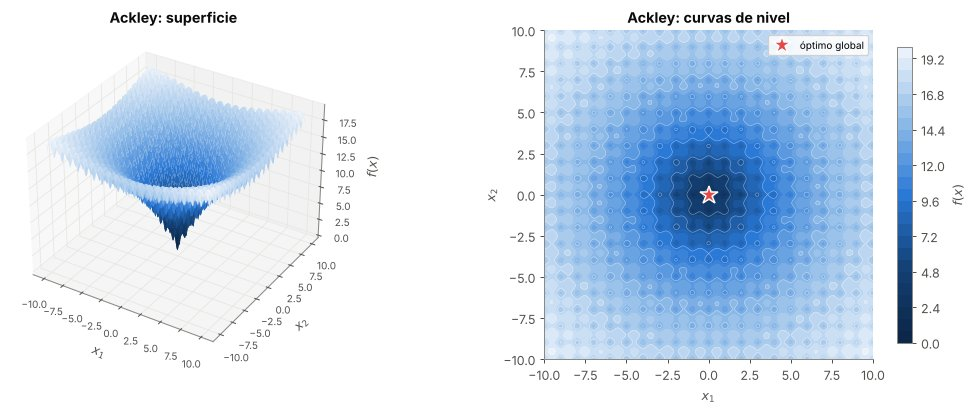

In [5]:
dibujar_paisaje('Ackley')

#### Código del equipo: Ackley

GA con **cruce aritmético** (con $\alpha$ aleatorio) y **mutación gaussiana** ($\sigma = 0.1$) sobre el dominio $[-100, 100]^2$, el mismo rango que usa CEC 2022.

*Nota de implementación: la condición de mejora usa `min(evaluation)` y la población es de 2 000 individuos (el original usaba 20 000) para que la celda corra en segundos en Python puro.*

In [6]:
import random
import numpy as np

random.seed(1); np.random.seed(1)  # semilla para reproducibilidad del notebook

def ackley_function(x, y):
    term1 = -20.0 * np.exp(-0.2 * np.sqrt(0.5 * (x**2 + y**2)))
    term2 = -np.exp(0.5 * (np.cos(2 * np.pi * x) + np.cos(2 * np.pi * y)))
    term3 = np.exp(1) + 20.0
    return term1 + term2 + term3

def create_individual():
    return np.array([random.uniform(-100, 100), random.uniform(-100, 100)])

def evaluate(individual):
    x, y = -individual
    return ackley_function(x, y)

def mutate(individual, MUTATION_RATE):
  if random.random() <= MUTATION_RATE:
    individual += np.random.normal(0, 0.1, size=individual.shape)
    individual = np.clip(individual, -100, 100)
  return individual

def combine(parent_a, parent_b, c_rate):
    if random.random() <= c_rate:
        alpha = random.random()
        offspring_a = alpha * parent_a + (1 - alpha) * parent_b
        offspring_b = alpha * parent_b + (1 - alpha) * parent_a
    else:
        offspring_a, offspring_b = np.copy(parent_a), np.copy(parent_b)
    return offspring_a, offspring_b

def select(population, evaluation, tournament_size):
    tournament = random.sample(range(len(population)), tournament_size)
    return population[min(tournament, key=lambda i: evaluation[i])]

def genetic_algorithm(population_size, c_rate, m_rate, generations):
    population = [create_individual() for _ in range(population_size)]
    best_individual = None
    best_evaluation = float('inf')

    for _ in range(generations):
        evaluation = [evaluate(ind) for ind in population]

        if min(evaluation) < best_evaluation:
            best_index = evaluation.index(min(evaluation))
            best_individual = population[best_index]
            best_evaluation = evaluation[best_index]

        new_population = []
        for _ in range(population_size // 2):
            parent_a = select(population, evaluation, 3)
            parent_b = select(population, evaluation, 3)
            offspring_a, offspring_b = combine(parent_a, parent_b, c_rate)
            new_population.extend([mutate(offspring_a, m_rate), mutate(offspring_b, m_rate)])

        population = new_population

    return best_individual, best_evaluation

POPULATION_SIZE = 2000
CROSSOVER_RATE = 0.7
MUTATION_RATE = 0.3
GENERATIONS = 100
TOURNAMENT_SIZE = 3

t0 = time.perf_counter()
best_solution, best_value = genetic_algorithm(POPULATION_SIZE, CROSSOVER_RATE, MUTATION_RATE, GENERATIONS)
print(best_solution)
print(best_value)
print(f'Tiempo: {time.perf_counter() - t0:.1f} s')

[6.19046217e-17 1.76499233e-17]
0.0
Tiempo: 1.4 s


In [7]:
print(f'Comprobación con la definición común en D dimensiones: f = {ackley(best_solution):.3e}')
print(f'Distancia al óptimo (0, 0): {np.linalg.norm(best_solution):.3e}')

Comprobación con la definición común en D dimensiones: f = 4.441e-16
Distancia al óptimo (0, 0): 6.437e-17


**Resultado.** Con 2 000 individuos y 100 generaciones (200 000 evaluaciones), nuestro GA llega a $(6.2\times10^{-17},\ 1.8\times10^{-17})$: **el óptimo global a precisión de máquina**, partiendo del dominio $[-100, 100]^2$ lleno de mínimos locales. Su función imprime 0.0 por el redondeo de $e + 20$; la definición común en $D$ dimensiones da $4.4\times10^{-16}$, exactamente el mismo valor que en el óptimo teórico (ver la verificación de la sección 1). El cruce aritmético funciona muy bien aquí: promediar padres que rodean al origen produce hijos cada vez más cerca de él.

---
### 2.2 Bent Cigar

$$
f(\mathbf{x}) = x_1^2 + 10^6\sum_{i=2}^{D}x_i^2
$$

**Propiedades**

* **Unimodal**: un solo mínimo, sin trampas locales.
* **Separable**: cada coordenada contribuye por su cuenta.
* **Mal condicionada**: en todas las direcciones salvo $x_1$ la pendiente es un millón de veces mayor. El valle es un "cigarro" larguísimo y estrechísimo; el reto no es encontrar el valle, sino avanzar a lo largo de él.
* **Mínimo global**: $f(\mathbf{0}) = 0$.
* En CEC 2022 es pieza de la híbrida F6 (40 % de las variables) y de las composiciones F9 y F12.

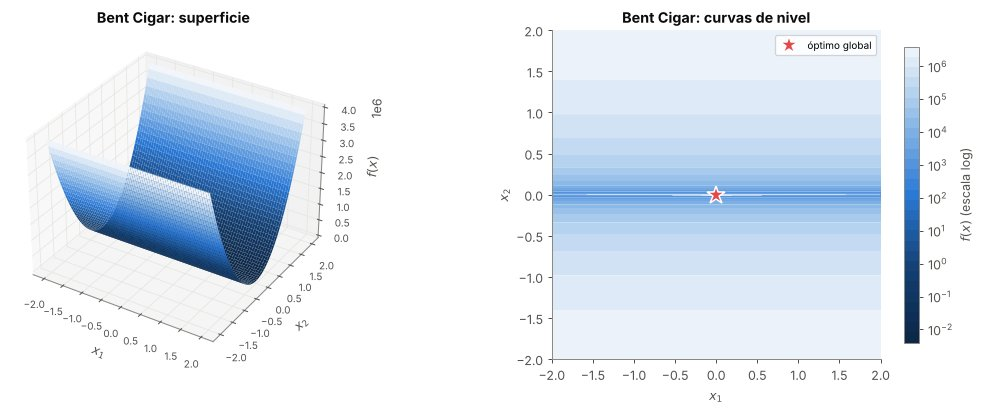

In [8]:
dibujar_paisaje('Bent Cigar')

#### Código del equipo: Bent Cigar

GA con **cruce de un punto** y **mutación uniforme** en $[-2, 2]^2$: población de 200 durante 2 000 generaciones.

In [9]:
import random
import numpy

random.seed(2); numpy.random.seed(2)  # semilla para reproducibilidad del notebook

minvalores, maxvalores = -2, 2

def bent_cigar_function(x, y):
    return x**2 + 1e6 * y**2

# Inicialización de un individuo: un punto (x, y) aleatorio dentro del dominio
def createIndividual():
    return numpy.array([numpy.random.uniform(minvalores, maxvalores) for _ in range(2)])

# Función de evaluación (fitness): valor de la función objetivo en el punto (a minimizar)
def evaluate(individual):
    x, y = individual
    result = bent_cigar_function(x, y)

    return result

# Función de cruce (one point crossover) entre dos individuos
def combine(parentA, parentB, cRate):
    if random.random() <= cRate:
        cPoint = numpy.random.randint(1, len(parentA))
        offspringA = numpy.append(parentA[:cPoint], parentB[cPoint:])
        offspringB = numpy.append(parentB[:cPoint], parentA[cPoint:])
    else:
        offspringA = numpy.copy(parentA)
        offspringB = numpy.copy(parentB)
    return offspringA, offspringB

# Función de mutación: reemplaza una coordenada por un valor aleatorio del dominio
def mutate(individual, mRate):
    for i in range(len(individual)):
        if random.random() <= mRate:
            # El nuevo valor se toma uniformemente dentro de los límites del dominio
            individual[i] = numpy.random.uniform(minvalores, maxvalores)
    return individual

# Función de selección por torneo
def select(population, evaluation, tournamentSize):
    winner = numpy.random.randint(0, len(population))
    for _ in range(tournamentSize - 1):
        rival = numpy.random.randint(0, len(population))
        if evaluation[rival] < evaluation[winner]:  # Cambiado a menor que para minimizar
            winner = rival
    return population[winner]

# Algoritmo genético para minimizar la función
def geneticAlgorithm(populationSize, cRate, mRate, generations):
    # Crear la población inicial
    population = [createIndividual() for _ in range(populationSize)]
    evaluation = [evaluate(ind) for ind in population]

    # Mantener registro del mejor individuo
    bestIndividual = population[numpy.argmin(evaluation)]  # Cambiado a argmin para minimizar
    bestEvaluation = min(evaluation)

    # Proceso evolutivo
    for _ in range(generations):
        newPopulation = []
        for _ in range(populationSize // 2):
            parentA = select(population, evaluation, 3)
            parentB = select(population, evaluation, 3)
            offspringA, offspringB = combine(parentA, parentB, cRate)
            newPopulation.append(offspringA)
            newPopulation.append(offspringB)

        population = [mutate(ind, mRate) for ind in newPopulation]
        evaluation = [evaluate(ind) for ind in population]

        # Actualizar el mejor individuo encontrado
        min_eval_idx = numpy.argmin(evaluation)  # Cambiado a argmin para minimizar
        if evaluation[min_eval_idx] < bestEvaluation:  # Cambiado a menor que para minimizar
            bestEvaluation = evaluation[min_eval_idx]
            bestIndividual = population[min_eval_idx]


    return bestIndividual, bestEvaluation

# Resolver el problema de minimización
t0 = time.perf_counter()
solution, evaluation = geneticAlgorithm(200, 0.7, 0.3, 2000)
print("Mejor solución encontrada:", solution)
print("Valor de la solución:", evaluation)
print(f'Tiempo: {time.perf_counter() - t0:.1f} s')

Mejor solución encontrada: [ 6.10469805e-05 -1.37207708e-05]
Valor de la solución: 0.00018826327828642882
Tiempo: 2.9 s


In [10]:
print(f'Comprobación con la definición común en D dimensiones: f = {bent_cigar(solution):.3e}')

Comprobación con la definición común en D dimensiones: f = 1.883e-04


**Resultado.** Nuestro GA llega a $f \approx 1.9\times10^{-4}$ en $(6.1\times10^{-5},\ -1.4\times10^{-5})$. El valor final lo domina el término $10^6 x_2^2$: aunque $x_2$ está a solo $1.4\times10^{-5}$ del óptimo, ese error se multiplica por un millón ($10^6 \cdot (1.37\times10^{-5})^2 \approx 1.9\times10^{-4}$), mientras que $x_1^2 \approx 4\times10^{-9}$. Ese es el efecto del mal condicionamiento: en Bent Cigar hay que acertar con muchísima más precisión en unas coordenadas que en otras.

---
### 2.3 Griewank

$$
f(\mathbf{x}) = \sum_{i=1}^{D}\frac{x_i^2}{4000} - \prod_{i=1}^{D}\cos\!\left(\frac{x_i}{\sqrt{i}}\right) + 1
$$

**Propiedades**

* **Multimodal**: un cuenco parabólico muy suave ($x^2/4000$) cubierto de ondulaciones del producto de cosenos, con muchos mínimos locales regularmente espaciados.
* **No separable**: el producto acopla todas las coordenadas (el $\sqrt{i}$ hace que cada eje ondule con distinta frecuencia).
* **Mínimo global**: $f(\mathbf{0}) = 0$.
* Curiosidad conocida: al crecer $D$ las ondulaciones se vuelven relativamente menos importantes y la función tiende a ser *más fácil*, no más difícil.
* En CEC 2022 es pieza de la composición F11 y, fusionada con Rosenbrock, de la híbrida F8.

Usamos el dominio $[-14, 14]^2$: en el intervalo $[-1, 1]$ solo se ve el fondo del cuenco central y no aparecen los mínimos locales que hacen interesante a esta función.

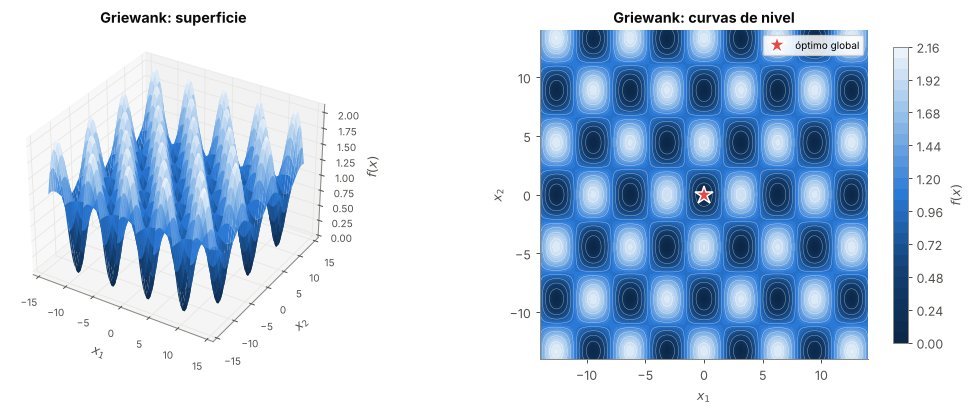

In [11]:
dibujar_paisaje('Griewank')

#### Código del equipo: Griewank

GA con **cruce de un punto**, **mutación uniforme** y **parada temprana** (se detiene tras 25 generaciones sin mejora). El programa resuelve el problema una vez y luego repite **30 corridas independientes** para reportar media y desviación estándar, la práctica que después adoptamos para la comparación general.

*Nota de implementación: el dominio de búsqueda es $[-14, 14]$ (el original usaba $[-1, 1]$).*

Mejor solución encontrada: [0.08185813 0.01583552]
Valor de la solución: 0.003412724499690878
Generaciones completadas: 74
Promedio valor minimo:  0.006931691933370144
Desviacion estandar:  0.003691625934247442


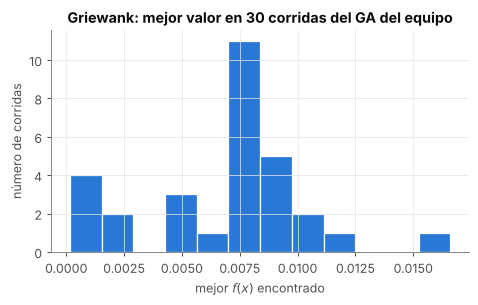

In [12]:
import random
import numpy
import math
import matplotlib.pyplot as plt

random.seed(3); numpy.random.seed(3)  # semilla para reproducibilidad del notebook

# Inicialización de un individuo: un punto (x, y) aleatorio dentro del dominio
def createIndividual():
    return numpy.array([numpy.random.uniform(-14, 14), numpy.random.uniform(-14, 14)])

# Función de evaluación (fitness): valor de la función de Griewank en el punto (a minimizar)
def evaluate(individual):
    b = 10
    x = individual[0]
    y = individual[1]
    valor_total = (x ** 2 + y ** 2)/4000.0 - math.cos(x) * math.cos(y / math.sqrt(2)) + 1.0
    return valor_total

# Función de cruce (one point crossover) entre dos individuos
def combine(parentA, parentB, cRate):
    if random.random() <= cRate:
        cPoint = numpy.random.randint(1, len(parentA))
        offspringA = numpy.append(parentA[:cPoint], parentB[cPoint:])
        offspringB = numpy.append(parentB[:cPoint], parentA[cPoint:])
    else:
        offspringA = numpy.copy(parentA)
        offspringB = numpy.copy(parentB)
    return offspringA, offspringB

# Función de mutación: reemplaza una coordenada por un valor aleatorio del dominio
def mutate(individual, mRate):
    for i in range(len(individual)):
        if random.random() <= mRate:
            # El nuevo valor se toma uniformemente dentro de los límites del dominio
            individual[i] = numpy.random.uniform(-14, 14)
    return individual

# Función de selección por torneo
def select(population, evaluation, tournamentSize):
    winner = numpy.random.randint(0, len(population))
    for _ in range(tournamentSize - 1):
        rival = numpy.random.randint(0, len(population))
        if evaluation[rival] < evaluation[winner]:
            winner = rival
    return population[winner]

# Algoritmo genético para minimizar la función
def geneticAlgorithm(populationSize, cRate, mRate, generations):
    # Crear la población inicial
    population = [createIndividual() for _ in range(populationSize)]
    evaluation = [evaluate(ind) for ind in population]

    # Mantener registro del mejor individuo
    bestIndividual = population[numpy.argmin(evaluation)]
    bestEvaluation = min(evaluation)

    # Variables para la parada temprana
    no_improvement_count = 0
    max_no_improvement = 25  # Número máximo de generaciones sin mejora
    current_generation = 0

    # Proceso evolutivo
    while current_generation < generations:
        newPopulation = []
        for _ in range(populationSize // 2):
            parentA = select(population, evaluation, 3)
            parentB = select(population, evaluation, 3)
            offspringA, offspringB = combine(parentA, parentB, cRate)
            newPopulation.append(offspringA)
            newPopulation.append(offspringB)

        population = [mutate(ind, mRate) for ind in newPopulation]
        evaluation = [evaluate(ind) for ind in population]

        # Actualizar el mejor individuo encontrado
        min_eval_idx = numpy.argmin(evaluation)
        if evaluation[min_eval_idx] < bestEvaluation:
            bestEvaluation = evaluation[min_eval_idx]
            bestIndividual = population[min_eval_idx]
            no_improvement_count = 0  # Reiniciar el contador si hay mejora
        else:
            no_improvement_count += 1

        # Verificar si se alcanzó el número máximo de generaciones sin mejora
        if no_improvement_count >= max_no_improvement:
            break

        current_generation += 1

    return bestIndividual, bestEvaluation, current_generation


# Resolver el problema una vez
solution, evaluation, generaciones_finalizadas = geneticAlgorithm(30, 0.7, 0.2, 1000)
print("Mejor solución encontrada:", solution)
print("Valor de la solución:", evaluation)
print("Generaciones completadas:", generaciones_finalizadas)


# Resolver el problema array
scores = []
for i in range(30):
    solution, evaluation, generaciones_finalizadas = geneticAlgorithm(30, 0.7, 0.2, 1000)
    scores.append(evaluation)
print("Promedio valor minimo: ", numpy.mean(scores))
print("Desviacion estandar: ", numpy.std(scores))
plt.figure(figsize=(6, 3.2))
plt.hist(scores, bins=12, edgecolor='white')
plt.title('Griewank: mejor valor en 30 corridas del GA del equipo')
plt.xlabel('mejor $f(x)$ encontrado'); plt.ylabel('número de corridas')
plt.show()
griewank_scores_equipo = numpy.array(scores)

**Resultado.** Con una población de solo 30 individuos y parada temprana (la corrida única terminó en 74 generaciones, unas 2 250 evaluaciones), el GA llega a $f \approx 3.4\times10^{-3}$. En las 30 corridas la media es $6.9\times10^{-3}$ con desviación estándar $3.7\times10^{-3}$. El histograma muestra por qué: una parte de las corridas llega cerca del óptimo y el grupo más numeroso se concentra alrededor de $0.0074$, el valor de los mínimos locales más cercanos al origen, en $(\pm\pi,\ \pm\pi\sqrt{2})$, precisamente los que se vuelven visibles al ampliar el dominio. Repetir 30 veces fue una decisión acertada: una sola corrida no permite distinguir entre suerte y consistencia.

---
### 2.4 HGBat

$$
f(\mathbf{x}) = \left|\left(\sum_{i=1}^{D}x_i^2\right)^2 - \left(\sum_{i=1}^{D}x_i\right)^2\right|^{1/2} + \frac{0.5\sum_{i=1}^{D}x_i^2 + \sum_{i=1}^{D}x_i}{D} + 0.5
$$

**Propiedades**

* Pariente de *HappyCat*; en las competencias CEC se clasifica como **multimodal y no separable**.
* El valor absoluto con raíz crea una **cresta no diferenciable** (donde $(\sum x_i^2)^2 = (\sum x_i)^2$): un pliegue que confunde a los métodos que siguen la pendiente.
* **Mínimo global**: $f(-1, \dots, -1) = 0$. Es la única función del grupo con el óptimo fuera del origen junto con Rosenbrock.
* En CEC 2022 es pieza de las híbridas F6 y F7 y de las composiciones F10 y F12.

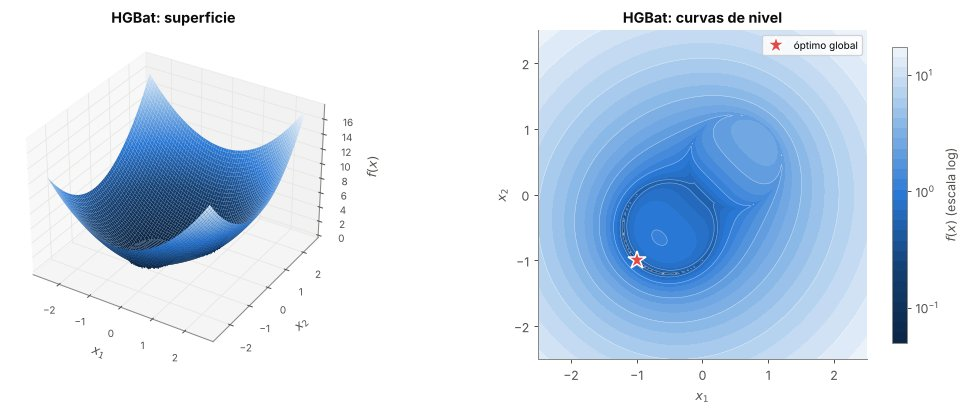

In [13]:
dibujar_paisaje('HGBat')

#### Código del equipo: HGBat

GA con **cruce de un punto**, **mutación uniforme** y selección por torneo con `random.sample`. El programa plantea la minimización como maximización de $-f$, un recurso clásico en algoritmos genéticos (que suelen formularse para maximizar la aptitud). Dominio $[-20, 20]^2$, población de 200 y 1 000 generaciones.

*Nota de implementación: `hgbat_function` usa la definición estándar de HGBat (la de la fórmula de arriba); la gráfica 3D del archivo original se dibuja arriba con el estilo común del notebook.*

In [14]:
import random
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# HGBat Function

random.seed(4); np.random.seed(4)  # semilla para reproducibilidad del notebook

# Definimos la HGBat Function como la nueva función objetivo
def hgbat_function(x):
    d = len(x)
    suma_cuadrados = np.sum(x ** 2)
    suma = np.sum(x)
    term1 = np.abs(suma_cuadrados ** 2 - suma ** 2) ** 0.5
    term2 = (0.5 * suma_cuadrados + suma) / d + 0.5
    return term1 + term2

# Parámetros de la funcion y rango de evaluacion
population_size = 200
crossover_rate = 0.9
mutation_rate = 0.05
mRate = 0.2
cRate = 0.8
generations = 1000
patience = 100
dimensiones = 2
lower_bound = -20
upper_bound = 20
tournament_size = 3

# GFuncion para crear un individuo aleatorio
def create_individual():
    return np.random.uniform(lower_bound, upper_bound, dimensiones)

# Función de crossover
def combine(parent_a, parent_b, c_rate):
    if random.random() <= c_rate:
        c_point = np.random.randint(1, len(parent_a))
        offspring_a = np.concatenate((parent_a[:c_point], parent_b[c_point:]))
        offspring_b = np.concatenate((parent_b[:c_point], parent_a[c_point:]))
    else:
        offspring_a, offspring_b = np.copy(parent_a), np.copy(parent_b)
    return offspring_a, offspring_b

# Función de mutación
def mutate(individual, m_rate):
    for i in range(len(individual)):
        if random.random() <= m_rate:
            individual[i] = np.random.uniform(lower_bound, upper_bound)
    return individual

# Evaluar un individuo usando la HGBat Function
def evaluate(individual):
    return -hgbat_function(individual)  # Queremos minimizar la función

# Selección por torneo
def select(population, evaluation, tournament_size):
    tournament = random.sample(range(len(population)), tournament_size)
    return population[max(tournament, key=lambda i: evaluation[i])]

# Algoritmo genético principal
def genetic_algorithm(population_size, c_rate, m_rate, generations):
    population = [create_individual() for _ in range(population_size)]
    best_individual = None
    best_evaluation = float('-inf')

    for gen in range(generations):
        evaluation = [evaluate(ind) for ind in population]

        if max(evaluation) > best_evaluation:
            best_index = evaluation.index(max(evaluation))
            best_individual = population[best_index]
            best_evaluation = evaluation[best_index]

        new_population = []
        for _ in range(population_size // 2):
            parent_a = select(population, evaluation, tournament_size)
            parent_b = select(population, evaluation, tournament_size)
            offspring_a, offspring_b = combine(parent_a, parent_b, c_rate)
            new_population.extend([mutate(offspring_a, m_rate), mutate(offspring_b, m_rate)])

        population = new_population

    return best_individual, -best_evaluation  # Volvemos a positivo el valor para la función objetivo

# Ejecutar el algoritmo genético
t0 = time.perf_counter()
best_solution, best_value = genetic_algorithm(population_size, crossover_rate, mutation_rate, generations)

# Mostrar el resultado final
print(f"Mejor solución: {best_solution}")
print(f"Valor óptimo encontrado: {best_value}")
print(f'Tiempo: {time.perf_counter() - t0:.1f} s')

Mejor solución: [-0.87533052 -1.09818228]
Valor óptimo encontrado: 0.07805225109638897
Tiempo: 1.5 s


In [15]:
print(f'Comprobación con la definición común en D dimensiones: f = {hgbat(best_solution):.3e}')
print(f'Distancia al óptimo (-1, -1): {np.linalg.norm(best_solution + 1):.3e}')

Comprobación con la definición común en D dimensiones: f = 7.805e-02
Distancia al óptimo (-1, -1): 1.587e-01


**Resultado.** Nuestro GA se acerca al óptimo $(-1, -1)$ hasta una distancia de 0.16, con $f \approx 0.078$, partiendo de $[-20, 20]^2$, un dominio con 64 veces el área de la ventana de la gráfica. El paisaje explica por qué el último tramo es el más difícil: alrededor del óptimo HGBat tiene un pliegue no diferenciable y una zona muy plana, y con cruce de un punto y mutación uniforme los hijos solo pueden recombinar coordenadas ya presentes o sortear valores nuevos en todo el dominio, así que afinar a escala de centésimas depende de que un sorteo caiga cerca. En la sección 4 se ve que el PSO, que se mueve con pasos continuos, afina mejor esta función en 2D.

---
### 2.5 High Conditioned Elliptic

$$
f(\mathbf{x}) = \sum_{i=1}^{D}\left(10^{6}\right)^{\frac{i-1}{D-1}}x_i^2
$$

**Propiedades**

* **Unimodal** y **separable**: un cuenco elíptico.
* **Número de condición $10^6$**: los pesos crecen geométricamente de $1$ (primer eje) a $10^6$ (último eje). Es la función estándar para medir si un optimizador sabe moverse en valles muy alargados.
* **Mínimo global**: $f(\mathbf{0}) = 0$.
* **Dato curioso**: en $D = 2$ los pesos son exactamente $1$ y $10^6$, así que la función coincide con Bent Cigar (lo verificamos numéricamente en la sección 1). A partir de $D = 3$ son distintas: Elliptic reparte los pesos de forma gradual y Bent Cigar pone $10^6$ en todos los ejes menos el primero.
* En CEC 2022 es pieza de las composiciones F9 (dos veces) y F12.

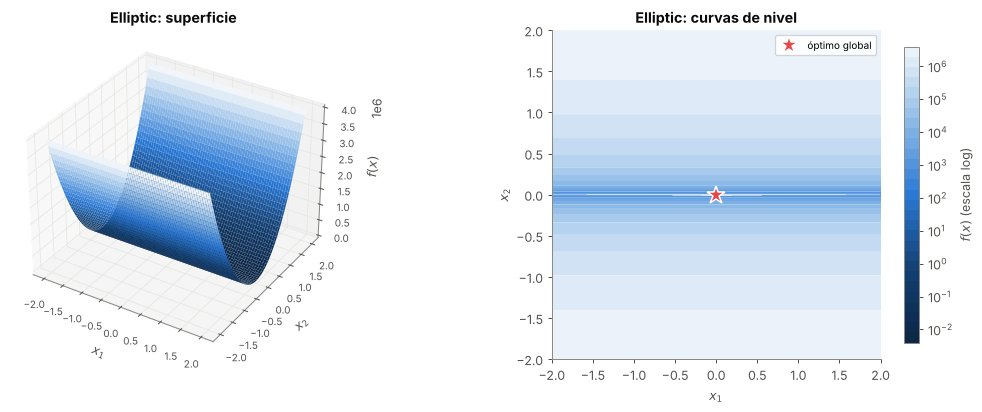

In [16]:
dibujar_paisaje('Elliptic', titulo='Elliptic')

#### Código del equipo: High Conditioned Elliptic

Misma estructura que el programa de HGBat (cruce de un punto, mutación uniforme, maximización de $-f$), ahora en el dominio $[-2, 2]^2$.

*Nota de implementación: el término de la suma es `a**(i/(d-1)) * x[i]**2`, que corresponde a la fórmula de arriba; la gráfica 3D del archivo original se dibuja arriba con el estilo común del notebook.*

In [17]:
import random
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# High Conditioned Elliptic Function

random.seed(5); np.random.seed(5)  # semilla para reproducibilidad del notebook

# Definimos la High Conditioned Elliptic Function que ahora sera nuestra funcion objetivo
def high_conditioned_elliptic_function(x):
    a = 1e6
    d = len(x)
    return np.sum([a**(i/(d-1)) * x[i]**2 for i in range(d)])

# Parámetros
population_size = 200
crossover_rate = 0.9
mutation_rate = 0.05
mRate = 0.2
cRate = 0.8
generations = 1000
patience = 100  # Número de generaciones sin mejora
dimensiones = 2
lower_bound = -2
upper_bound = 2
tournament_size = 3

# Funcion para crear un individuo aleatorio
def create_individual():
    return np.random.uniform(lower_bound, upper_bound, dimensiones)

# Función de crossover
def combine(parent_a, parent_b, c_rate):
    if random.random() <= c_rate:
        c_point = np.random.randint(1, len(parent_a))
        offspring_a = np.concatenate((parent_a[:c_point], parent_b[c_point:]))
        offspring_b = np.concatenate((parent_b[:c_point], parent_a[c_point:]))
    else:
        offspring_a, offspring_b = np.copy(parent_a), np.copy(parent_b)
    return offspring_a, offspring_b

# Función de mutación
def mutate(individual, m_rate):
    for i in range(len(individual)):
        if random.random() <= m_rate:
            individual[i] = np.random.uniform(lower_bound, upper_bound)
    return individual

# Evaluamos individuo co la High Conditioned Elliptic Function
def evaluate(individual):
    return -high_conditioned_elliptic_function(individual)  # Minimizamos funcion (agregamos -)

# Selección por torneo
def select(population, evaluation, tournament_size):
    tournament = random.sample(range(len(population)), tournament_size)
    return population[max(tournament, key=lambda i: evaluation[i])]

# Algoritmo Genético
def genetic_algorithm(population_size, c_rate, m_rate, generations):
    population = [create_individual() for _ in range(population_size)]
    best_individual = None
    best_evaluation = float('-inf')

    for gen in range(generations):
        evaluation = [evaluate(ind) for ind in population]

        if max(evaluation) > best_evaluation:
            best_index = evaluation.index(max(evaluation))
            best_individual = population[best_index]
            best_evaluation = evaluation[best_index]

        new_population = []
        for _ in range(population_size // 2):
            parent_a = select(population, evaluation, tournament_size)
            parent_b = select(population, evaluation, tournament_size)
            offspring_a, offspring_b = combine(parent_a, parent_b, c_rate)
            new_population.extend([mutate(offspring_a, m_rate), mutate(offspring_b, m_rate)])

        population = new_population

    return best_individual, -best_evaluation  # Volvemos a positivo el valor para la función objetivo

# Encontramos solucion con algoritmo
t0 = time.perf_counter()
best_solution, best_value = genetic_algorithm(population_size, crossover_rate, mutation_rate, generations)

print(f"Mejor solución: {best_solution}")
print(f"Valor óptimo encontrado: {best_value}")
print(f'Tiempo: {time.perf_counter() - t0:.1f} s')

Mejor solución: [-2.14199521e-04 -4.21576714e-05]
Valor óptimo encontrado: 0.0017773151406561835
Tiempo: 1.2 s


In [18]:
print(f'Comprobación con la definición común en D dimensiones: f = {elliptic(best_solution):.3e}')

Comprobación con la definición común en D dimensiones: f = 1.777e-03


**Resultado.** El GA llega a $f \approx 1.8\times10^{-3}$ en $(-2.1\times10^{-4},\ -4.2\times10^{-5})$. Igual que en Bent Cigar (que en 2D es la misma función), el valor final lo domina el término con peso $10^6$: $10^6 \cdot (4.2\times10^{-5})^2 \approx 1.8\times10^{-3}$, mientras que el primer término aporta solo $\approx 5\times10^{-8}$.

---
### 2.6 Rastrigin

$$
f(\mathbf{x}) = 10D + \sum_{i=1}^{D}\left[x_i^2 - 10\cos(2\pi x_i)\right]
$$

**Propiedades**

* **Altamente multimodal**: una "caja de huevos" con un mínimo local cerca de cada punto de coordenadas enteras; en $[-5.12, 5.12]^D$ hay del orden de $11^D$ de ellos.
* **Separable**: se puede optimizar coordenada por coordenada (lo que favorece al cruce de un punto, que intercambia coordenadas completas).
* **Mínimo global**: $f(\mathbf{0}) = 0$.
* CEC 2022 usa una versión **no continua** de Rastrigin como F4, y Rastrigin es pieza de las híbridas F6 y F7 y de las composiciones F10, F11 y F12: es la pieza más usada del banco.

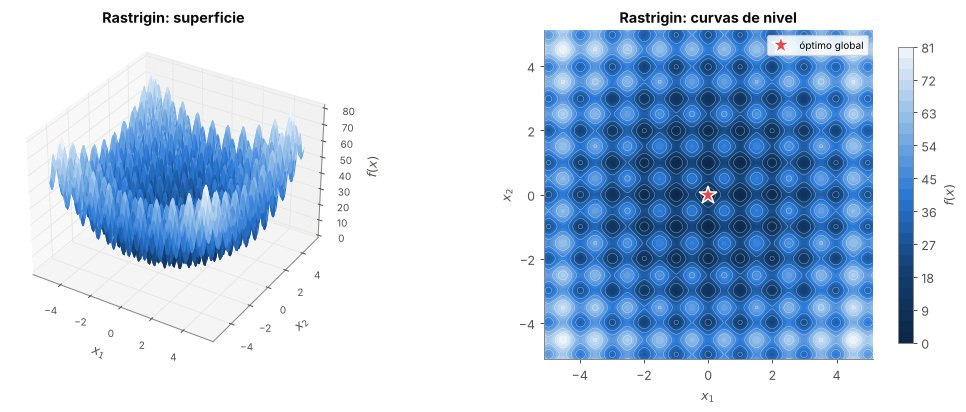

In [19]:
dibujar_paisaje('Rastrigin')

#### Código del equipo: Rastrigin

Mismo GA que en Bent Cigar (cruce de un punto y mutación uniforme), ahora en $[-5.12, 5.12]^2$, con población de 200 y 2 000 generaciones.

In [20]:
import random
import numpy

random.seed(6); numpy.random.seed(6)  # semilla para reproducibilidad del notebook

minvalores, maxvalores = -5.12, 5.12

def rastrigin_function(x, y, A=10):
    return 2*A + x**2 - A*numpy.cos(2*numpy.pi*x) + y**2 - A*numpy.cos(2*numpy.pi*y)

# Inicialización de un individuo: un punto (x, y) aleatorio dentro del dominio
def createIndividual():
    return numpy.array([numpy.random.uniform(minvalores, maxvalores) for _ in range(2)])

# Función de evaluación (fitness): valor de la función objetivo en el punto (a minimizar)
def evaluate(individual):
    x, y = individual
    result = rastrigin_function(x, y)

    return result

# Función de cruce (one point crossover) entre dos individuos
def combine(parentA, parentB, cRate):
    if random.random() <= cRate:
        cPoint = numpy.random.randint(1, len(parentA))
        offspringA = numpy.append(parentA[:cPoint], parentB[cPoint:])
        offspringB = numpy.append(parentB[:cPoint], parentA[cPoint:])
    else:
        offspringA = numpy.copy(parentA)
        offspringB = numpy.copy(parentB)
    return offspringA, offspringB

# Función de mutación: reemplaza una coordenada por un valor aleatorio del dominio
def mutate(individual, mRate):
    for i in range(len(individual)):
        if random.random() <= mRate:
            # El nuevo valor se toma uniformemente dentro de los límites del dominio
            individual[i] = numpy.random.uniform(minvalores, maxvalores)
    return individual

# Función de selección por torneo
def select(population, evaluation, tournamentSize):
    winner = numpy.random.randint(0, len(population))
    for _ in range(tournamentSize - 1):
        rival = numpy.random.randint(0, len(population))
        if evaluation[rival] < evaluation[winner]:  # Cambiado a menor que para minimizar
            winner = rival
    return population[winner]

# Algoritmo genético para minimizar la función
def geneticAlgorithm(populationSize, cRate, mRate, generations):
    # Crear la población inicial
    population = [createIndividual() for _ in range(populationSize)]
    evaluation = [evaluate(ind) for ind in population]

    # Mantener registro del mejor individuo
    bestIndividual = population[numpy.argmin(evaluation)]  # Cambiado a argmin para minimizar
    bestEvaluation = min(evaluation)

    # Proceso evolutivo
    for _ in range(generations):
        newPopulation = []
        for _ in range(populationSize // 2):
            parentA = select(population, evaluation, 3)
            parentB = select(population, evaluation, 3)
            offspringA, offspringB = combine(parentA, parentB, cRate)
            newPopulation.append(offspringA)
            newPopulation.append(offspringB)

        population = [mutate(ind, mRate) for ind in newPopulation]
        evaluation = [evaluate(ind) for ind in population]

        # Actualizar el mejor individuo encontrado
        min_eval_idx = numpy.argmin(evaluation)  # Cambiado a argmin para minimizar
        if evaluation[min_eval_idx] < bestEvaluation:  # Cambiado a menor que para minimizar
            bestEvaluation = evaluation[min_eval_idx]
            bestIndividual = population[min_eval_idx]


    return bestIndividual, bestEvaluation

# Resolver el problema de minimización
t0 = time.perf_counter()
solution, evaluation = geneticAlgorithm(200, 0.7, 0.3, 2000)
print("Mejor solución encontrada:", solution)
print("Valor de la solución:", evaluation)
print(f'Tiempo: {time.perf_counter() - t0:.1f} s')

Mejor solución encontrada: [-4.12209570e-05  3.26004473e-05]
Valor de la solución: 5.479503073502201e-07
Tiempo: 3.2 s


In [21]:
print(f'Comprobación con la definición común en D dimensiones: f = {rastrigin(solution):.3e}')

Comprobación con la definición común en D dimensiones: f = 5.480e-07


**Resultado.** Nuestro GA llega a $f \approx 5.5\times10^{-7}$ en $(-4.1\times10^{-5},\ 3.3\times10^{-5})$: encontró la cuenca del óptimo global entre los aproximadamente 120 mínimos locales del dominio y bajó hasta su fondo. Rastrigin es separable, y el cruce de un punto aprovecha justo eso: un hijo puede heredar una buena $x_1$ de un padre y una buena $x_2$ del otro. Esta ventaja reaparece con fuerza en la comparación en $D = 10$.

---
### 2.7 Rosenbrock

$$
f(\mathbf{x}) = \sum_{i=1}^{D-1}\left[\,b\,(x_{i+1} - x_i^2)^2 + (x_i - 1)^2\,\right], \qquad b = 100
$$

**Propiedades**

* El famoso **"valle del plátano"**: encontrar el valle es fácil; recorrerlo hasta el mínimo es difícil porque es estrecho, curvo y casi plano en el fondo.
* **No separable**: cada término encadena dos coordenadas consecutivas.
* Unimodal en 2 y 3 dimensiones; a partir de $D = 4$ aparece un mínimo local cerca de $(-1, 1, \dots, 1)$.
* **Mínimo global**: $f(1, \dots, 1) = 0$.
* $b$ controla qué tan estrecho es el valle; el valor estándar, y el que usa CEC 2022 en su **F2**, es $b = 100$. También es pieza de las composiciones F9 y F11.

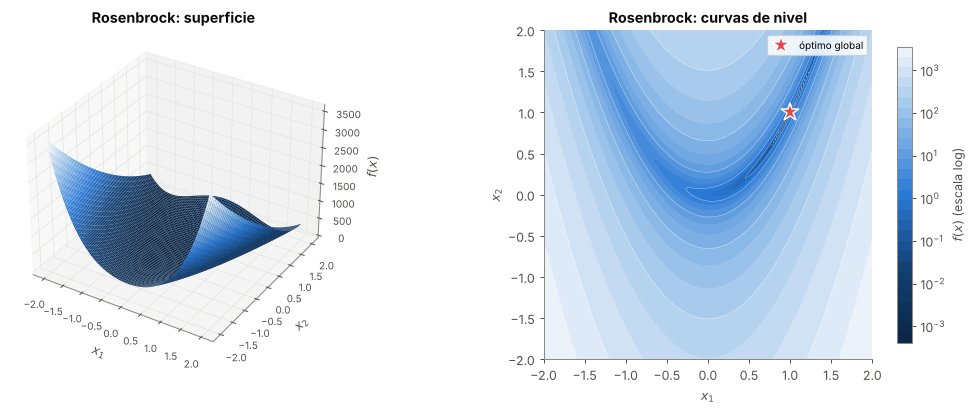

In [22]:
dibujar_paisaje('Rosenbrock')

#### Código del equipo: Rosenbrock

Misma estructura que el programa de Griewank: cruce de un punto, mutación uniforme, parada temprana tras 25 generaciones sin mejora y 30 corridas independientes. La población inicial se toma en $[0, 2]^2$.

*Nota de implementación: se usa $b = 100$, el valor estándar (el original usaba $b = 10$).*

Mejor solución encontrada: [0.83472652 0.69909863]
Valor de la solución: 0.02785833445594971
Generaciones completadas: 64
Promedio valor minimo:  0.04477952665221963
Desviacion estandar:  0.062204204948682174


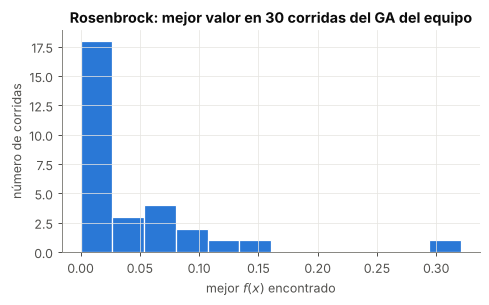

In [23]:
import random
import numpy
import matplotlib.pyplot as plt

random.seed(7); numpy.random.seed(7)  # semilla para reproducibilidad del notebook

# Inicialización de un individuo: un punto (x, y) aleatorio dentro del dominio
def createIndividual():
    return numpy.array([numpy.random.uniform(0, 2), numpy.random.uniform(0, 2)])

# Función de evaluación (fitness): valor de la función de Rosenbrock en el punto (a minimizar)
def evaluate(individual):
    b = 100
    x = individual[0]
    y = individual[1]
    valor_total = (x-1)**2 + b*(y-x**2)**2
    return valor_total

# Función de cruce (one point crossover) entre dos individuos
def combine(parentA, parentB, cRate):
    if random.random() <= cRate:
        cPoint = numpy.random.randint(1, len(parentA))
        offspringA = numpy.append(parentA[:cPoint], parentB[cPoint:])
        offspringB = numpy.append(parentB[:cPoint], parentA[cPoint:])
    else:
        offspringA = numpy.copy(parentA)
        offspringB = numpy.copy(parentB)
    return offspringA, offspringB

# Función de mutación: reemplaza una coordenada por un valor aleatorio del dominio
def mutate(individual, mRate):
    for i in range(len(individual)):
        if random.random() <= mRate:
            # El nuevo valor se toma uniformemente dentro de los límites del dominio
            individual[i] = numpy.random.uniform(0, 2)
    return individual

# Función de selección por torneo
def select(population, evaluation, tournamentSize):
    winner = numpy.random.randint(0, len(population))
    for _ in range(tournamentSize - 1):
        rival = numpy.random.randint(0, len(population))
        if evaluation[rival] < evaluation[winner]:
            winner = rival
    return population[winner]

# Algoritmo genético para minimizar la función
def geneticAlgorithm(populationSize, cRate, mRate, generations):
    # Crear la población inicial
    population = [createIndividual() for _ in range(populationSize)]
    evaluation = [evaluate(ind) for ind in population]

    # Mantener registro del mejor individuo
    bestIndividual = population[numpy.argmin(evaluation)]
    bestEvaluation = min(evaluation)

    # Variables para la parada temprana
    no_improvement_count = 0
    max_no_improvement = 25  # Número máximo de generaciones sin mejora
    current_generation = 0

    # Proceso evolutivo
    while current_generation < generations:
        newPopulation = []
        for _ in range(populationSize // 2):
            parentA = select(population, evaluation, 3)
            parentB = select(population, evaluation, 3)
            offspringA, offspringB = combine(parentA, parentB, cRate)
            newPopulation.append(offspringA)
            newPopulation.append(offspringB)

        population = [mutate(ind, mRate) for ind in newPopulation]
        evaluation = [evaluate(ind) for ind in population]

        # Actualizar el mejor individuo encontrado
        min_eval_idx = numpy.argmin(evaluation)
        if evaluation[min_eval_idx] < bestEvaluation:
            bestEvaluation = evaluation[min_eval_idx]
            bestIndividual = population[min_eval_idx]
            no_improvement_count = 0  # Reiniciar el contador si hay mejora
        else:
            no_improvement_count += 1

        # Verificar si se alcanzó el número máximo de generaciones sin mejora
        if no_improvement_count >= max_no_improvement:
            break

        current_generation += 1

    return bestIndividual, bestEvaluation, current_generation


# Resolver el problema una vez
solution, evaluation, generaciones_finalizadas = geneticAlgorithm(30, 0.7, 0.2, 1000)
print("Mejor solución encontrada:", solution)
print("Valor de la solución:", evaluation)
print("Generaciones completadas:", generaciones_finalizadas)

# Resolver el problema muchas veces
scores = []
for i in range(30):
    solution, evaluation, generaciones_finalizadas = geneticAlgorithm(30, 0.7, 0.2, 1000)
    scores.append(evaluation)
print("Promedio valor minimo: ", numpy.mean(scores))
print("Desviacion estandar: ", numpy.std(scores))
plt.figure(figsize=(6, 3.2))
plt.hist(scores, bins=12, edgecolor='white')
plt.title('Rosenbrock: mejor valor en 30 corridas del GA del equipo')
plt.xlabel('mejor $f(x)$ encontrado'); plt.ylabel('número de corridas')
plt.show()
rosenbrock_scores_equipo = numpy.array(scores)

**Resultado.** Con $b = 100$ el valle es estrecho y la parada temprana actúa pronto: la corrida única termina en 64 generaciones con $f \approx 0.028$ en $(0.83,\ 0.70)$, un punto en el fondo del valle (casi exactamente sobre $x_2 = x_1^2$) pero todavía lejos de $(1, 1)$. En 30 corridas, la media es $0.045$ y la desviación estándar $0.062$. Es el comportamiento típico en Rosenbrock: encontrar el valle es rápido; recorrerlo exige muchos pasos pequeños y consecutivos, y 25 generaciones sin mejora pueden llegar antes que el siguiente paso.

### Resumen de los programas del equipo

| Función | Mejor $f$ encontrado | Evaluaciones aprox. |
|---|---|---|
| Ackley | $4.4\times10^{-16}$ (precisión de máquina) | 200 000 |
| Bent Cigar | $1.9\times10^{-4}$ | 400 000 |
| Griewank | $3.4\times10^{-3}$ (media de 30 corridas: $6.9\times10^{-3}$) | ≈ 2 250 por corrida |
| HGBat | $7.8\times10^{-2}$ | 200 000 |
| High Conditioned Elliptic | $1.8\times10^{-3}$ | 200 000 |
| Rastrigin | $5.5\times10^{-7}$ | 400 000 |
| Rosenbrock | $2.8\times10^{-2}$ (media de 30 corridas: $4.5\times10^{-2}$) | ≈ 1 950 por corrida |

Los siete programas terminan en la cuenca del óptimo global de su función, cinco de ellos con $f < 10^{-2}$. Como los presupuestos van de unas 2 000 a 400 000 evaluaciones, estos números no son comparables entre sí; para comparar con justicia, la siguiente sección pone a todos los algoritmos en igualdad de condiciones.

## 3. Un GA unificado, un PSO global y búsqueda aleatoria

Para comparar de forma justa necesitamos que todos los algoritmos corran sobre **las mismas funciones, el mismo dominio y el mismo presupuesto de evaluaciones**, con semillas controladas. Reunimos las dos variantes de GA del equipo en **una sola implementación vectorizada** y la enfrentamos a una **versión vectorizada de un PSO global estándar** y a la **búsqueda aleatoria** (la línea base que cualquier método debería superar). Los programas originales del equipo, escritos con ciclos de Python, son ideales para entender cada paso; las versiones vectorizadas con `numpy` permiten correr cientos de experimentos en segundos.

### 3.1 GA unificado

* **Selección**: torneo de tamaño 3 (como en todos los programas del equipo).
* **Variante `'un_punto'`** (seis de los siete programas): cruce de un punto con probabilidad $p_c = 0.7$; mutación uniforme por gen con probabilidad $p_m = \min(0.2, 1/D)$.
* **Variante `'aritmetico'`** (programa de Ackley): cruce aritmético $\alpha\mathbf{a} + (1-\alpha)\mathbf{b}$ con $\alpha \sim U(0,1)$ y $p_c = 0.7$; mutación gaussiana del individuo completo con probabilidad $0.3$ y $\sigma = 1\,\%$ del rango del dominio.
* **Elitismo de 1**: el mejor individuo pasa intacto a la siguiente generación (los programas originales guardaban al mejor aparte; aquí además sigue reproduciéndose).

In [24]:
def ga(f, lo, hi, D, rng, presupuesto, n_pob=50, variante='un_punto', p_cruce=0.7,
       p_mut=None, sigma=0.01, torneo=3, elitismo=1):
    '''Algoritmo genético real (minimización). Devuelve el mejor punto, su valor
    y el historial del mejor valor encontrado frente al número de evaluaciones.'''
    if p_mut is None:
        p_mut = min(0.2, 1.0 / D) if variante == 'un_punto' else 0.3
    n_gen = presupuesto // n_pob - 1
    P = rng.uniform(lo, hi, size=(n_pob, D))
    F = f(P)
    i0 = F.argmin(); mejor_x, mejor_f = P[i0].copy(), F[i0]
    historial = [mejor_f]
    filas = np.arange(n_pob)
    for _ in range(n_gen):
        # Selección por torneo: n_pob torneos de 'torneo' individuos cada uno
        cand = rng.integers(0, n_pob, size=(n_pob, torneo))
        padres = P[cand[filas, F[cand].argmin(axis=1)]]
        A, B = padres[0::2], padres[1::2]
        cruza = rng.random(len(A)) < p_cruce
        if variante == 'un_punto':
            corte = rng.integers(1, D, size=len(A)) if D > 1 else np.ones(len(A), int)
            mascara = (np.arange(D) >= corte[:, None]) & cruza[:, None]
            H = np.vstack([np.where(mascara, B, A), np.where(mascara, A, B)])
            muta = rng.random(H.shape) < p_mut
            H[muta] = rng.uniform(lo, hi, size=muta.sum())
        elif variante == 'aritmetico':
            alfa = np.where(cruza, rng.random(len(A)), 1.0)[:, None]
            H = np.vstack([alfa * A + (1 - alfa) * B, alfa * B + (1 - alfa) * A])
            muta = rng.random(len(H)) < p_mut
            H[muta] += rng.normal(0.0, sigma * (hi - lo), size=(muta.sum(), D))
            H = np.clip(H, lo, hi)
        else:
            raise ValueError(variante)
        FH = f(H)
        if elitismo:
            orden_padres = np.argsort(F)[:elitismo]
            peores_hijos = np.argsort(FH)[-elitismo:]
            H[peores_hijos], FH[peores_hijos] = P[orden_padres], F[orden_padres]
        P, F = H, FH
        i0 = F.argmin()
        if F[i0] < mejor_f:
            mejor_x, mejor_f = P[i0].copy(), F[i0]
        historial.append(mejor_f)
    evals = n_pob * np.arange(1, len(historial) + 1)
    return dict(x=mejor_x, f=mejor_f, evals=evals, hist=np.array(historial))

### 3.2 PSO global estándar

El equipo también programó un PSO: la versión original de 1995, que presentamos en la sección 6 junto con su extensión a problemas de ingeniería. Para las comparaciones masivas de las secciones 4 y 5 usamos esta versión vectorizada con los coeficientes de constricción, la variante moderna más usada como referencia.

Cada partícula $i$ tiene posición $\mathbf{x}_i$, velocidad $\mathbf{v}_i$ y memoria de su mejor posición $\mathbf{p}_i$; el enjambre comparte la mejor posición global $\mathbf{g}$:

$$
\mathbf{v}_i \leftarrow w\,\mathbf{v}_i + c_1 r_1 (\mathbf{p}_i - \mathbf{x}_i) + c_2 r_2 (\mathbf{g} - \mathbf{x}_i), \qquad \mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i
$$

con los coeficientes de constricción de Clerc y Kennedy: $w = 0.729$, $c_1 = c_2 = 1.494$, y $r_1, r_2 \sim U(0,1)$ por coordenada. Esa es toda la "biología": **inercia** (seguir volando), **memoria** (volver a donde me fue bien) y **comunicación** (ir hacia donde le fue bien al grupo).

* **Velocidad máxima**: 25 % del rango del dominio por coordenada.
* **Bordes**: si una partícula se sale, rebota (su posición se refleja hacia adentro) y su velocidad se invierte y se amortigua a la mitad.

In [25]:
def pso_global(f, lo, hi, D, rng, presupuesto, n_part=50, w=0.729, c1=1.494, c2=1.494,
        vmax_frac=0.25, amortiguamiento=0.5):
    '''PSO global (topología gbest) con velocidad máxima y rebote amortiguado.'''
    n_iter = presupuesto // n_part - 1
    vmax = vmax_frac * (hi - lo)
    X = rng.uniform(lo, hi, size=(n_part, D))
    V = rng.uniform(-vmax, vmax, size=(n_part, D)) * 0.5
    F = f(X)
    P, FP = X.copy(), F.copy()                    # memoria personal
    g = FP.argmin(); G, FG = P[g].copy(), FP[g]   # mejor global
    historial = [FG]
    for _ in range(n_iter):
        r1 = rng.random((n_part, D)); r2 = rng.random((n_part, D))
        V = w * V + c1 * r1 * (P - X) + c2 * r2 * (G - X)
        np.clip(V, -vmax, vmax, out=V)
        X = X + V
        # Rebote amortiguado en los bordes
        fuera_alto, fuera_bajo = X > hi, X < lo
        X = np.where(fuera_alto, 2 * hi - X, X)
        X = np.where(fuera_bajo, 2 * lo - X, X)
        V = np.where(fuera_alto | fuera_bajo, -amortiguamiento * V, V)
        np.clip(X, lo, hi, out=X)
        F = f(X)
        mejora = F < FP
        P[mejora], FP[mejora] = X[mejora], F[mejora]
        g = FP.argmin()
        if FP[g] < FG:
            G, FG = P[g].copy(), FP[g]
        historial.append(FG)
    evals = n_part * np.arange(1, len(historial) + 1)
    return dict(x=G, f=FG, evals=evals, hist=np.array(historial))


def busqueda_aleatoria(f, lo, hi, D, rng, presupuesto, lote=50):
    '''Muestrea puntos uniformes en el dominio y conserva el mejor.'''
    n_lotes = presupuesto // lote
    mejores = np.array([f(rng.uniform(lo, hi, size=(lote, D))).min() for _ in range(n_lotes)])
    hist = np.minimum.accumulate(mejores)
    return dict(x=None, f=hist[-1], evals=lote * np.arange(1, n_lotes + 1), hist=hist)


ALGORITMOS = {
    'GA (un punto + uniforme)':    lambda f, lo, hi, D, rng, B: ga(f, lo, hi, D, rng, B, variante='un_punto'),
    'GA (aritmético + gaussiana)': lambda f, lo, hi, D, rng, B: ga(f, lo, hi, D, rng, B, variante='aritmetico'),
    'PSO global':                  lambda f, lo, hi, D, rng, B: pso_global(f, lo, hi, D, rng, B),
    'Búsqueda aleatoria':          lambda f, lo, hi, D, rng, B: busqueda_aleatoria(f, lo, hi, D, rng, B),
}
COLORES = dict(zip(ALGORITMOS, [AZUL, NARANJA, AQUA, GRIS]))
CORTOS = dict(zip(ALGORITMOS, ['GA 1P', 'GA arit.', 'PSO', 'Aleat.']))

# Prueba rápida de reproducibilidad: misma semilla -> mismo resultado
r1 = pso_global(rastrigin, -5.12, 5.12, 2, np.random.default_rng(123), 2000)['f']
r2 = pso_global(rastrigin, -5.12, 5.12, 2, np.random.default_rng(123), 2000)['f']
print('Reproducible:', r1 == r2, f'(f = {r1:.3e})')

Reproducible: True (f = 2.953e-03)


### 3.3 Protocolo experimental

* **30 corridas independientes** por función y algoritmo, cada una con su propia semilla `default_rng([semilla, función, algoritmo, corrida])`.
* **Presupuesto**: 10 000 evaluaciones de la función en 2D (población o enjambre de 50 durante 200 iteraciones).
* Se registra el **mejor valor encontrado** después de cada generación o iteración.

In [26]:
def experimento(D, presupuesto, corridas, semilla=2022, funciones=NOMBRES, rotaciones=None,
                algoritmos=None):
    '''Corre todas las combinaciones función x algoritmo x corrida.
    rotaciones: dict opcional {nombre: matriz ortogonal} para evaluar f(R x).'''
    algoritmos = algoritmos or list(ALGORITMOS)
    filas, curvas = [], {}
    for i_f, nombre in enumerate(funciones):
        info = FUNCIONES[nombre]
        f, (lo, hi) = info['f'], info['dominio']
        if rotaciones is not None and nombre in rotaciones:
            R = rotaciones[nombre]
            f = (lambda base, R: (lambda X: base(X @ R.T)))(info['f'], R)
        for i_a, alg in enumerate(algoritmos):
            hist = []
            for c in range(corridas):
                rng = np.random.default_rng([semilla, D, i_f, list(ALGORITMOS).index(alg), c])
                res = ALGORITMOS[alg](f, lo, hi, D, rng, presupuesto)
                filas.append(dict(función=nombre, algoritmo=alg, corrida=c, mejor=res['f']))
                hist.append(res['hist'])
            curvas[(nombre, alg)] = (res['evals'], np.array(hist))
    return pd.DataFrame(filas), curvas


t0 = time.perf_counter()
resultados_2d, curvas_2d = experimento(D=2, presupuesto=10_000, corridas=30)
print(f'{len(resultados_2d)} corridas en {time.perf_counter() - t0:.1f} s')

840 corridas en 5.5 s


## 4. Comparación en 2D

### 4.1 Curvas de convergencia

Mejor valor encontrado frente al número de evaluaciones, en escala logarítmica. La línea es la **mediana de las 30 corridas** y la banda sombreada va del cuartil 25 % al 75 %. Los valores se recortan en $10^{-16}$ para poder dibujarlos en escala log (por debajo de eso estamos en el ruido del punto flotante).

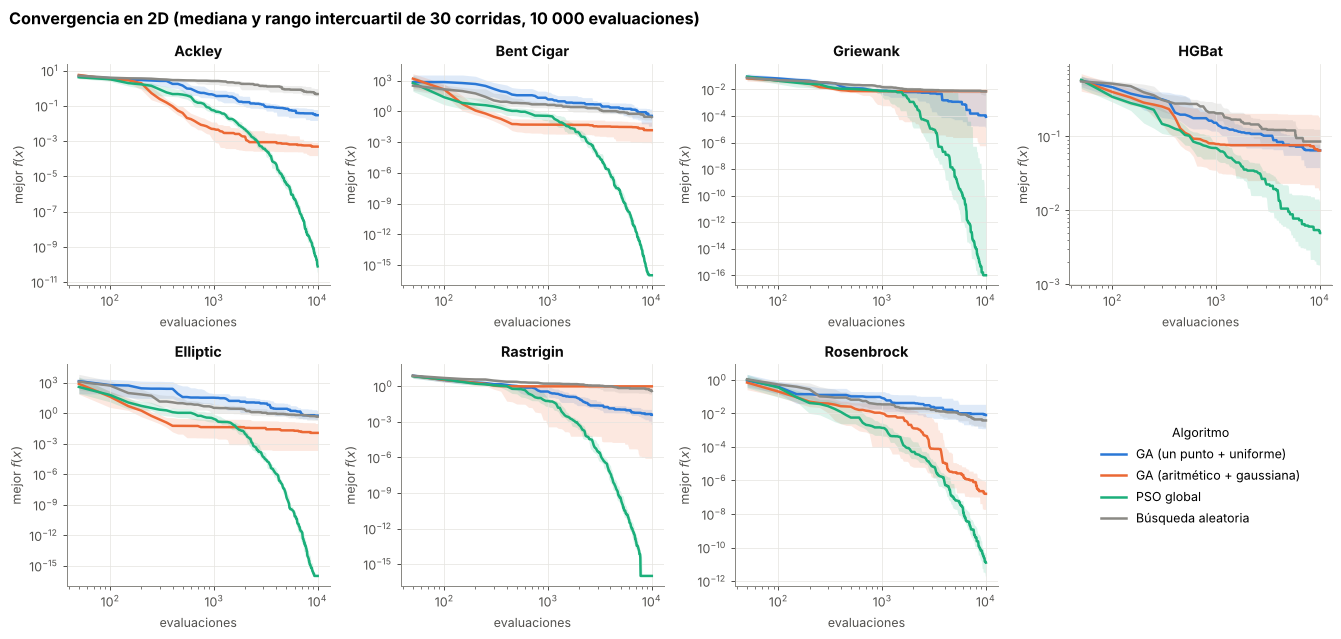

In [27]:
PISO = 1e-16

def dibujar_convergencia(curvas, funciones, titulo):
    fig, ejes = plt.subplots(2, 4, figsize=(15, 7.2))
    ejes = ejes.ravel()
    for ax, nombre in zip(ejes, funciones):
        for alg in ALGORITMOS:
            if (nombre, alg) not in curvas:
                continue
            evals, H = curvas[(nombre, alg)]
            H = np.maximum(H, PISO)
            q25, q50, q75 = np.percentile(H, [25, 50, 75], axis=0)
            ax.plot(evals, q50, color=COLORES[alg], lw=2, label=alg)
            ax.fill_between(evals, q25, q75, color=COLORES[alg], alpha=0.15, lw=0)
        ax.set_yscale('log'); ax.set_xscale('log')
        ax.set_title(nombre)
        ax.set_xlabel('evaluaciones')
        ax.set_ylabel('mejor $f(x)$')
    for ax in ejes[len(funciones):]:
        ax.axis('off')
    manejadores, etiquetas = ejes[0].get_legend_handles_labels()
    ejes[-1].legend(manejadores, etiquetas, loc='center', fontsize=10, title='Algoritmo')
    fig.suptitle(titulo, fontsize=13, fontweight='bold', x=0.01, ha='left')
    fig.tight_layout()
    plt.show()

dibujar_convergencia(curvas_2d, NOMBRES, 'Convergencia en 2D (mediana y rango intercuartil de 30 corridas, 10 000 evaluaciones)')

### 4.2 Estadística de 30 corridas

Igual que hacían los programas de Griewank y Rosenbrock, resumimos cada combinación con **media, desviación estándar y mediana** del mejor valor final. La mediana es la medida más robusta: una sola corrida atascada en un mínimo local puede disparar la media.

In [28]:
pd.set_option('display.float_format', lambda v: f'{v:.3e}')
pd.set_option('display.width', 160)

def tabla_estadistica(df):
    t = (df.groupby(['función', 'algoritmo'], sort=False)['mejor']
           .agg(media='mean', desv_est='std', mediana='median', mínimo='min', máximo='max'))
    return t

estad_2d = tabla_estadistica(resultados_2d)
estad_2d

media  desv_est   mediana    mínimo    máximo
función    algoritmo                                                                    
Ackley     GA (un punto + uniforme)    3.856e-02 2.873e-02 2.922e-02 5.242e-03 9.946e-02
           GA (aritmético + gaussiana) 8.656e-02 4.709e-01 4.833e-04 4.523e-09 2.580e+00
           PSO global                  1.329e-10 1.453e-10 7.781e-11 3.059e-12 5.043e-10
           Búsqueda aleatoria          6.490e-01 4.969e-01 4.633e-01 2.073e-02 1.741e+00
Bent Cigar GA (un punto + uniforme)    1.361e+00 2.113e+00 3.560e-01 1.126e-06 8.899e+00
           GA (aritmético + gaussiana) 1.281e-01 2.582e-01 1.435e-02 3.454e-08 9.392e-01
           PSO global                  2.182e-17 5.419e-17 3.557e-18 3.383e-23 2.810e-16
           Búsqueda aleatoria          4.839e-01 5.520e-01 2.774e-01 9.565e-05 2.223e+00
Griewank   GA (un punto + uniforme)    2.999e-03 3.683e-03 8.622e-05 4.421e-07 7.649e-03
           GA (aritmético + gaussiana) 7.150e-03 7.045e-03 7.396e-03 4.803e-12 2.713e-02
           PSO global                  1.233e-03 2.803e-03 0.000e+00 0.000e+00 7.396e-03
           Búsqueda aleatoria          5.914e-03 2.788e-03 7.088e-03 1.021e-04 9.245e-03
HGBat      GA (un punto + uniforme)    5.948e-02 2.635e-02 6.496e-02 1.091e-02 1.040e-01
           GA (aritmético + gaussiana) 1.051e-01 1.021e-01 6.444e-02 4.678e-04 3.134e-01
           PSO global                  8.242e-03 9.113e-03 4.950e-03 5.927e-06 2.941e-02
           Búsqueda aleatoria          9.161e-02 4.194e-02 8.546e-02 1.496e-02 1.692e-01
Elliptic   GA (un punto + uniforme)    1.223e+00 1.450e+00 5.662e-01 3.083e-02 5.635e+00
           GA (aritmético + gaussiana) 9.336e-02 1.967e-01 1.147e-02 9.654e-11 7.764e-01
           PSO global                  3.373e-17 6.267e-17 6.146e-18 1.563e-19 2.611e-16
           Búsqueda aleatoria          5.369e-01 4.591e-01 4.512e-01 1.080e-02 1.810e+00
Rastrigin  GA (un punto + uniforme)    8.306e-03 1.527e-02 3.927e-03 5.906e-06 8.176e-02
           GA (aritmético + gaussiana) 8.291e-01 1.080e+00 9.950e-01 5.992e-10 4.975e+00
           PSO global                  0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
           Búsqueda aleatoria          5.135e-01 3.840e-01 3.996e-01 5.805e-02 1.219e+00
Rosenbrock GA (un punto + uniforme)    2.472e-02 3.276e-02 8.033e-03 8.077e-05 1.089e-01
           GA (aritmético + gaussiana) 1.330e-06 3.094e-06 1.604e-07 7.727e-12 1.458e-05
           PSO global                  4.945e-11 9.856e-11 1.255e-11 9.875e-14 4.911e-10
           Búsqueda aleatoria          5.348e-03 5.119e-03 3.827e-03 6.305e-04 2.156e-02

In [29]:
medianas_2d = (resultados_2d.pivot_table(index='función', columns='algoritmo', values='mejor',
                                          aggfunc='median', sort=False)[list(ALGORITMOS)])
print('Mediana del mejor valor final (D = 2, 30 corridas, 10 000 evaluaciones)')
display(medianas_2d)

ganador_2d = medianas_2d.idxmin(axis=1)
print('\nAlgoritmo con la menor mediana por función:')
for fn, alg in ganador_2d.items():
    print(f'  {fn:<11} -> {alg}')

Mediana del mejor valor final (D = 2, 30 corridas, 10 000 evaluaciones)


algoritmo,GA (un punto + uniforme),GA (aritmético + gaussiana),PSO global,Búsqueda aleatoria
función,,,,
Ackley,2.922e-02,4.833e-04,7.781e-11,4.633e-01
Bent Cigar,3.560e-01,1.435e-02,3.557e-18,2.774e-01
Griewank,8.622e-05,7.396e-03,0.000e+00,7.088e-03
HGBat,6.496e-02,6.444e-02,4.950e-03,8.546e-02
Elliptic,5.662e-01,1.147e-02,6.146e-18,4.512e-01
Rastrigin,3.927e-03,9.950e-01,0.000e+00,3.996e-01
Rosenbrock,8.033e-03,1.604e-07,1.255e-11,3.827e-03



Algoritmo con la menor mediana por función:
  Ackley      -> PSO global
  Bent Cigar  -> PSO global
  Griewank    -> PSO global
  HGBat       -> PSO global
  Elliptic    -> PSO global
  Rastrigin   -> PSO global
  Rosenbrock  -> PSO global


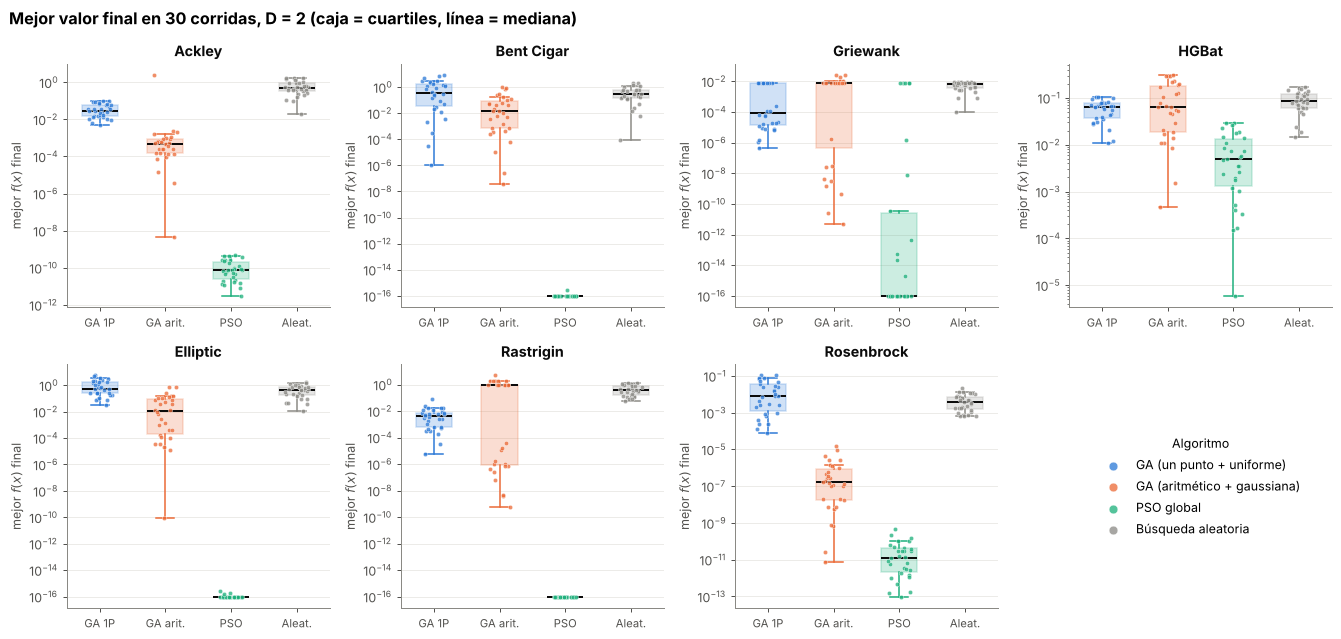

In [30]:
def dibujar_cajas(df, funciones, titulo, algoritmos=None):
    algoritmos = algoritmos or [a for a in ALGORITMOS if a in set(df['algoritmo'])]
    fig, ejes = plt.subplots(2, 4, figsize=(15, 7.2))
    ejes = ejes.ravel()
    rng_jitter = np.random.default_rng(7)
    for ax, nombre in zip(ejes, funciones):
        sub = df[df['función'] == nombre]
        datos = [np.maximum(sub.loc[sub['algoritmo'] == a, 'mejor'].to_numpy(), PISO) for a in algoritmos]
        cajas = ax.boxplot(datos, positions=range(len(algoritmos)), widths=0.55, showfliers=False,
                           patch_artist=True, medianprops=dict(color=TINTA, lw=1.6))
        for caja, a in zip(cajas['boxes'], algoritmos):
            caja.set(facecolor=COLORES[a], alpha=0.22, edgecolor=COLORES[a], lw=1.2)
        for parte in ('whiskers', 'caps'):
            for k, linea in enumerate(cajas[parte]):
                linea.set(color=COLORES[algoritmos[k // 2]], lw=1.2)
        for j, (a, d) in enumerate(zip(algoritmos, datos)):
            ax.scatter(j + rng_jitter.uniform(-0.18, 0.18, len(d)), d, s=12, color=COLORES[a],
                       alpha=0.75, edgecolors='white', linewidths=0.4, zorder=3, label=a)
        ax.set_yscale('log')
        ax.set_xticks(range(len(algoritmos)))
        ax.set_xticklabels([CORTOS[a] for a in algoritmos], fontsize=9)
        ax.set_title(nombre)
        ax.set_ylabel('mejor $f(x)$ final')
        ax.grid(axis='x', visible=False)
    for ax in ejes[len(funciones):]:
        ax.axis('off')
    manejadores, etiquetas = ejes[0].get_legend_handles_labels()
    ejes[-1].legend(manejadores, etiquetas, loc='center', fontsize=10, title='Algoritmo', markerscale=2)
    fig.suptitle(titulo, fontsize=13, fontweight='bold', x=0.01, ha='left')
    fig.tight_layout()
    plt.show()

dibujar_cajas(resultados_2d, NOMBRES, 'Mejor valor final en 30 corridas, D = 2 (caja = cuartiles, línea = mediana)')

**Lectura de los resultados en 2D.** * Con el mismo presupuesto de 10 000 evaluaciones, **el PSO obtiene la menor mediana en las siete funciones**. En cuatro (Bent Cigar, Elliptic, Griewank y Rastrigin) llega al nivel del redondeo numérico y en Ackley y Rosenbrock queda por debajo de $10^{-10}$. HGBat es la función más difícil en 2D para todos: ahí el PSO se queda en $5\times10^{-3}$.
* **Las dos variantes del GA se reparten el terreno.** El cruce aritmético gana donde hay que afinar a lo largo de un valle (Ackley, Bent Cigar, Elliptic y Rosenbrock, donde llega a $1.6\times10^{-7}$), porque promediar padres genera pasos cada vez más finos. El cruce de un punto gana en las funciones con mínimos locales en rejilla (Rastrigin y Griewank), donde la variante aritmética tiende a converger antes de tiempo: su mediana en Rastrigin, 0.995, es exactamente el valor del mínimo local vecino en $(\pm 1, 0)$. En HGBat empatan ($6.5\times10^{-2}$ y $6.4\times10^{-2}$).
* Con este presupuesto pequeño, en Bent Cigar, Elliptic y Rosenbrock la variante de un punto queda al nivel de la búsqueda aleatoria: en 2D el cruce de un punto solo puede intercambiar $x_1$ y $x_2$ entre padres, así que la precisión fina depende de la mutación uniforme. Con presupuestos mayores, como los de los programas originales (hasta 400 000 evaluaciones), el mismo esquema llega a $10^{-4}$ o menos, como se vio en la sección 2.
* Las cajas muestran lo que la media esconde: la variante aritmética tiene mucha dispersión (en Ackley va de $4.5\times10^{-9}$ a 2.6), señal de que a veces converge prematuramente. Por eso la mediana es la medida principal de la tabla.

## 5. Más allá de 2D

En dos dimensiones casi cualquier método encuentra el valle: el dominio es pequeño y la búsqueda aleatoria ya cubre buena parte de él. CEC 2022 evalúa en $D = 10$ y $D = 20$, donde el volumen del espacio crece exponencialmente (la "maldición de la dimensionalidad") y las diferencias entre algoritmos se vuelven claras.

### 5.1 Las mismas funciones en $D = 10$

Mismos algoritmos y dominios, presupuesto de **20 000 evaluaciones** (población de 50 durante 400 iteraciones) y **15 corridas** por combinación para mantener el notebook ágil.

In [31]:
t0 = time.perf_counter()
resultados_10d, curvas_10d = experimento(D=10, presupuesto=20_000, corridas=15)
print(f'{len(resultados_10d)} corridas en {time.perf_counter() - t0:.1f} s')

medianas_10d = (resultados_10d.pivot_table(index='función', columns='algoritmo', values='mejor',
                                            aggfunc='median', sort=False)[list(ALGORITMOS)])
print('Mediana del mejor valor final (D = 10, 15 corridas, 20 000 evaluaciones)')
display(medianas_10d)
ganador_10d = medianas_10d.idxmin(axis=1)
print('\nAlgoritmo con la menor mediana por función:')
for fn, alg in ganador_10d.items():
    print(f'  {fn:<11} -> {alg}')

420 corridas en 6.3 s
Mediana del mejor valor final (D = 10, 15 corridas, 20 000 evaluaciones)


algoritmo,GA (un punto + uniforme),GA (aritmético + gaussiana),PSO global,Búsqueda aleatoria
función,,,,
Ackley,1.937e-01,2.820e+00,8.901e-11,8.310e+00
Bent Cigar,4.470e+02,1.025e+01,1.829e-16,1.245e+06
Griewank,5.132e-02,2.000e-02,5.410e-02,5.851e-01
HGBat,2.168e-01,4.501e-01,2.858e-01,1.609e+00
Elliptic,9.364e+00,7.662e+01,3.808e-18,8.478e+03
Rastrigin,5.828e-01,1.294e+01,4.981e+00,6.967e+01
Rosenbrock,5.627e+00,8.537e+00,2.883e+00,1.457e+02



Algoritmo con la menor mediana por función:
  Ackley      -> PSO global
  Bent Cigar  -> PSO global
  Griewank    -> GA (aritmético + gaussiana)
  HGBat       -> GA (un punto + uniforme)
  Elliptic    -> PSO global
  Rastrigin   -> GA (un punto + uniforme)
  Rosenbrock  -> PSO global


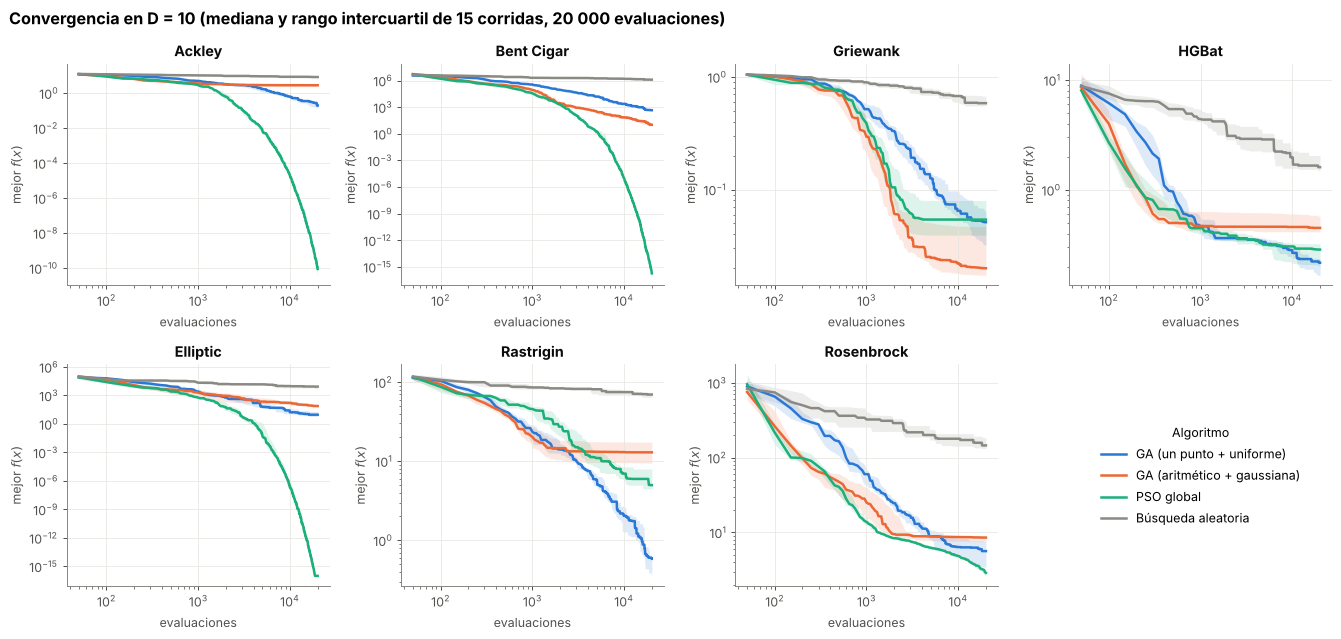

In [32]:
dibujar_convergencia(curvas_10d, NOMBRES, 'Convergencia en D = 10 (mediana y rango intercuartil de 15 corridas, 20 000 evaluaciones)')

**Lectura de los resultados en $D = 10$.** * El PSO sigue dominando en **Ackley, Bent Cigar, Elliptic y Rosenbrock** (en las tres primeras llega a $10^{-10}$ o menos), pero **ya no gana siempre**.
* En **Rastrigin**, la función separable por excelencia, gana el **GA de un punto** (mediana 0.58 frente a 4.98 del PSO y 12.9 del GA aritmético): intercambiar coordenadas completas es justo la operación correcta cuando cada coordenada se puede optimizar por separado. El GA de un punto también gana en **HGBat** (0.22 frente a 0.29 del PSO).
* En **Griewank** gana el **GA aritmético** (0.020 frente a 0.051–0.054 de los otros dos).
* La búsqueda aleatoria queda claramente atrás en todas las funciones; en Bent Cigar su mediana es $1.2\times10^{6}$, entre 3 y 22 órdenes de magnitud peor que los algoritmos bioinspirados. En 10 dimensiones ya no basta con "lanzar dardos".

### 5.2 El efecto de rotar el paisaje

En una función **separable** cada coordenada se puede optimizar por separado. El cruce de un punto aprovecha justo eso: intercambia coordenadas completas entre padres, así que si un padre tiene una buena $x_1$ y el otro una buena $x_2$, un hijo puede heredar ambas.

CEC 2022 **rota** todas sus funciones: en lugar de $f(\mathbf{x})$ evalúa $f(\mathbf{M}\mathbf{x})$ con $\mathbf{M}$ una matriz ortogonal. La forma del paisaje no cambia (una rotación conserva distancias y el valor del óptimo), pero sus ejes ya no coinciden con los de las variables: las variables dejan de ser independientes. (CEC además **desplaza** el óptimo, $f(\mathbf{M}(\mathbf{x} - \mathbf{o}))$, para que no esté en el centro del dominio; aquí nos concentramos en la rotación.)

Una matriz ortogonal aleatoria se obtiene con la descomposición QR de una matriz de números normales:

M =
 [[-0.79   0.613]
 [-0.613 -0.79 ]]
M^T M = I : True | det(M) = 1.0
Ángulo de giro: -142.2°


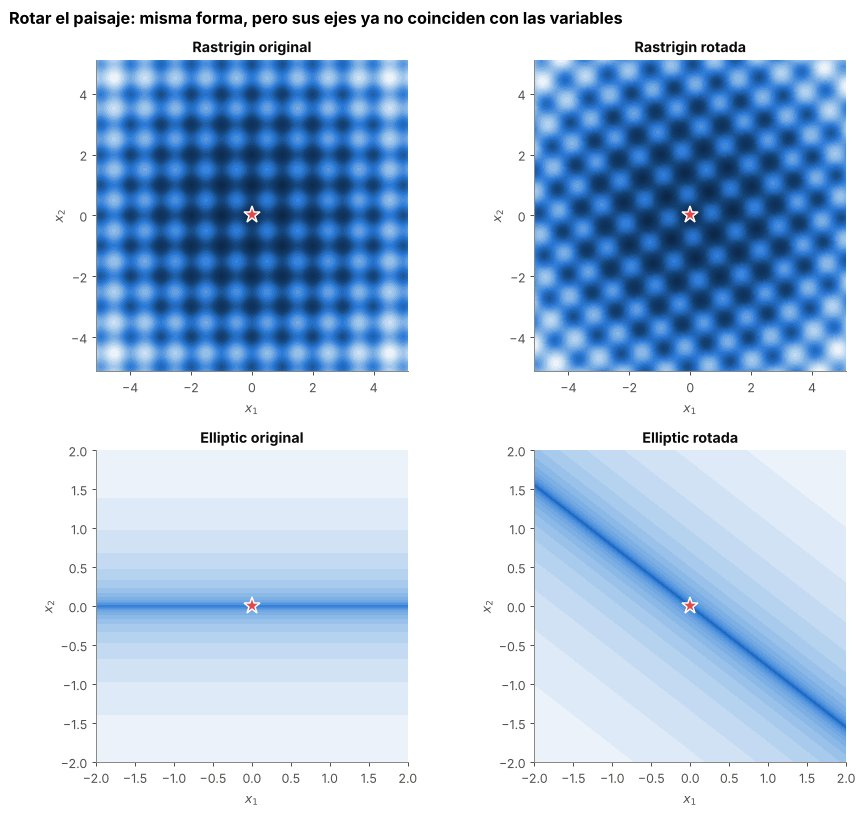

In [33]:
def matriz_ortogonal(D, rng):
    Q, R = np.linalg.qr(rng.normal(size=(D, D)))
    Q = Q * np.sign(np.diag(R))   # corrige signos para que la distribución sea uniforme
    if np.linalg.det(Q) < 0:      # nos quedamos con una rotación propia (det = +1)
        Q[:, 0] = -Q[:, 0]
    return Q

rng_rot = np.random.default_rng(2022)
M2 = matriz_ortogonal(2, rng_rot)
print('M =\n', np.round(M2, 3))
print('M^T M = I :', np.allclose(M2.T @ M2, np.eye(2)), '| det(M) =', round(np.linalg.det(M2), 6))
print(f'Ángulo de giro: {np.degrees(np.arctan2(M2[1, 0], M2[0, 0])):.1f}°')

fig, ejes = plt.subplots(2, 2, figsize=(10, 9.2))
for fila, nombre in enumerate(['Rastrigin', 'Elliptic']):
    info = FUNCIONES[nombre]
    lo, hi = info['dominio']
    for col, (rot, etiqueta) in enumerate([(None, 'original'), (M2, 'rotada')]):
        f = info['f'] if rot is None else (lambda X, b=info['f'], R=rot: b(X @ R.T))
        XX, YY, Z = malla(f, lo, hi, 241)
        ax = ejes[fila, col]
        if info['log']:
            piso = max(Z[Z > 0].min(), Z.max() * 1e-9)
            cf = ax.contourf(XX, YY, np.clip(Z, piso, None), levels=np.geomspace(piso, Z.max(), 30),
                             cmap=CMAP, norm=LogNorm())
        else:
            cf = ax.contourf(XX, YY, Z, levels=30, cmap=CMAP)
        ax.plot(0, 0, marker='*', ms=14, color=OPTIMO, mec='white', mew=1.2)
        ax.set_aspect('equal'); ax.grid(False)
        ax.set_title(f'{nombre} {etiqueta}')
        ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
fig.suptitle('Rotar el paisaje: misma forma, pero sus ejes ya no coinciden con las variables',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
mostrar(fig)

Ahora medimos el efecto en $D = 10$ con dos funciones separables (Rastrigin y Elliptic) y una no separable (Ackley) como control, cuyo óptimo está en el origen (la rotación lo deja en su lugar). Cada algoritmo corre 15 veces sobre la versión original y sobre la versión rotada con la misma matriz $\mathbf{M}$.

In [34]:
FUNCS_ROT = ['Rastrigin', 'Elliptic', 'Ackley']
ALGS_ROT = ['GA (un punto + uniforme)', 'GA (aritmético + gaussiana)', 'PSO global']
M10 = matriz_ortogonal(10, np.random.default_rng(10))

t0 = time.perf_counter()
sin_rot, _ = experimento(D=10, presupuesto=20_000, corridas=15, funciones=FUNCS_ROT, algoritmos=ALGS_ROT)
con_rot, _ = experimento(D=10, presupuesto=20_000, corridas=15, funciones=FUNCS_ROT, algoritmos=ALGS_ROT,
                         rotaciones={n: M10 for n in FUNCS_ROT})
print(f'Experimento de rotación: {time.perf_counter() - t0:.1f} s')

sin_rot['paisaje'], con_rot['paisaje'] = 'original', 'rotado'
rot_df = pd.concat([sin_rot, con_rot], ignore_index=True)
tabla_rot = rot_df.pivot_table(index=['función', 'algoritmo'], columns='paisaje', values='mejor',
                               aggfunc='median', sort=False)
tabla_rot['rotado / original'] = tabla_rot['rotado'] / np.maximum(tabla_rot['original'], PISO)
print('Mediana del mejor valor final en D = 10 (15 corridas)')
tabla_rot

Experimento de rotación: 5.1 s
Mediana del mejor valor final en D = 10 (15 corridas)


paisaje                                original    rotado  rotado / original
función   algoritmo                                                         
Rastrigin GA (un punto + uniforme)    4.420e-01 1.768e+01          4.000e+01
          GA (aritmético + gaussiana) 1.195e+01 1.196e+01          1.001e+00
          PSO global                  6.965e+00 1.492e+01          2.143e+00
Elliptic  GA (un punto + uniforme)    6.379e+00 6.671e+02          1.046e+02
          GA (aritmético + gaussiana) 6.977e+01 7.244e+01          1.038e+00
          PSO global                  4.923e-18 5.308e+01          5.308e+17
Ackley    GA (un punto + uniforme)    2.654e-01 2.085e+00          7.855e+00
          GA (aritmético + gaussiana) 3.577e+00 3.223e+00          9.012e-01
          PSO global                  1.179e-10 1.242e-10          1.053e+00

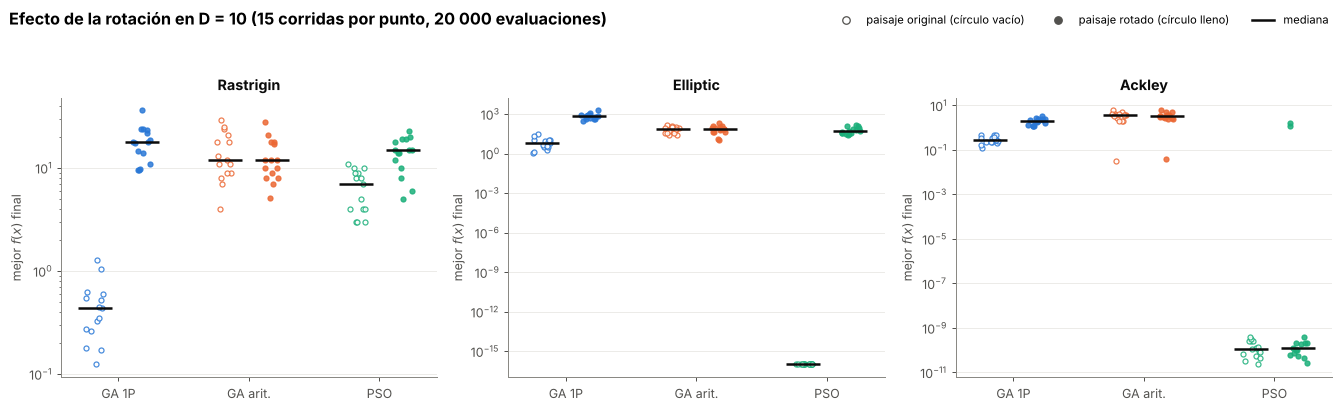

In [35]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, nombre in zip(ejes, FUNCS_ROT):
    for j, alg in enumerate(ALGS_ROT):
        for k, paisaje in enumerate(['original', 'rotado']):
            d = rot_df[(rot_df['función'] == nombre) & (rot_df['algoritmo'] == alg) & (rot_df['paisaje'] == paisaje)]['mejor']
            d = np.maximum(d.to_numpy(), PISO)
            x = j + (k - 0.5) * 0.36
            relleno = COLORES[alg] if paisaje == 'rotado' else 'white'
            ax.scatter(np.full(len(d), x) + np.random.default_rng(j * 2 + k).uniform(-0.07, 0.07, len(d)), d,
                       s=16, facecolor=relleno, edgecolor=COLORES[alg], linewidths=1.0, alpha=0.85, zorder=3)
            ax.hlines(np.median(d), x - 0.13, x + 0.13, color=TINTA, lw=2, zorder=4)
    ax.set_yscale('log')
    ax.set_xticks(range(len(ALGS_ROT)))
    ax.set_xticklabels([CORTOS[a] for a in ALGS_ROT])
    ax.set_title(nombre)
    ax.set_ylabel('mejor $f(x)$ final')
    ax.grid(axis='x', visible=False)
from matplotlib.lines import Line2D
leyenda = [Line2D([], [], marker='o', ls='none', mfc='white', mec=TINTA_2, label='paisaje original (círculo vacío)'),
           Line2D([], [], marker='o', ls='none', mfc=TINTA_2, mec=TINTA_2, label='paisaje rotado (círculo lleno)'),
           Line2D([], [], color=TINTA, lw=2, label='mediana')]
fig.legend(handles=leyenda, loc='upper right', ncol=3, fontsize=9, bbox_to_anchor=(0.995, 0.995))
fig.suptitle('Efecto de la rotación en D = 10 (15 corridas por punto, 20 000 evaluaciones)',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**Lectura.** * **GA de un punto**: es el que más pierde. En Rastrigin su mediana pasa de 0.44 a 17.7 (40 veces peor) y en Elliptic de 6.4 a 667 (unas 100 veces peor): con el paisaje rotado, intercambiar coordenadas ya no equivale a combinar "soluciones parciales" buenas. Incluso en Ackley, que no es separable pero tiene una parte separable (la suma de cosenos), empeora unas 8 veces.
* **GA aritmético**: prácticamente no cambia (cocientes entre 0.90 y 1.04). Promediar dos padres y sumar ruido gaussiano isotrópico no depende de la orientación de los ejes, así que el algoritmo es casi invariante a rotaciones; la contraparte es que tampoco aprovecha la separabilidad cuando existe.
* **PSO**: en Ackley la mediana no cambia (aunque dos corridas rotadas se quedan en un mínimo local), pero en Elliptic pasa de $5\times10^{-18}$ a 53 y en Rastrigin de 7.0 a 14.9. El PSO estándar tampoco es invariante a rotaciones: los números aleatorios $r_1, r_2$ se sortean por coordenada, lo que favorece moverse a lo largo de los ejes. En una función separable y mal condicionada eso es una ventaja enorme; cuando el valle queda en diagonal, desaparece.

Por esto CEC rota sus funciones: un algoritmo que solo brilla cuando las variables son independientes está aprovechando una propiedad que los problemas reales casi nunca tienen.

## 6. Del enjambre a la ingeniería

El PSO nació en 1995, cuando Kennedy y Eberhart simplificaron un modelo de bandadas de aves hasta quedarse con lo esencial: cada partícula recuerda dónde le fue mejor y sabe dónde le fue mejor al grupo. El equipo programó ese algoritmo original sobre la función de Ackley y después lo llevó a cuatro problemas clásicos de **diseño mecánico con restricciones**, siguiendo el artículo:

> L. C. Cagnina, S. C. Esquivel y C. A. Coello Coello (2008). *Solving Engineering Optimization Problems with the Simple Constrained Particle Swarm Optimizer*. **Informatica** 32: 319–326.

Los cuatro problemas (viga soldada, recipiente a presión, reductor de velocidad y resorte) son la prueba estándar para optimizadores con restricciones: mezclan variables continuas y discretas, tienen funciones de costo y restricciones no lineales, y en el óptimo varias restricciones quedan **activas** (justo en el límite).

### 6.1 Nuestro PSO en Ackley

Es el PSO de 1995 tal cual:

$$
v_{id} \leftarrow v_{id} + c_1 r_1 (p_{id} - x_{id}) + c_2 r_2 (g_d - x_{id}), \qquad x_{id} \leftarrow x_{id} + v_{id}
$$

* **sin factor de inercia** (la velocidad anterior se conserva completa), con $c_1 = c_2 = 2$;
* **velocidad máxima** de 0.1 por coordenada;
* **rebote** en las paredes del dominio $[-5, 5]^2$: la posición se refleja hacia adentro y la velocidad cambia de signo;
* cada partícula es un **diccionario** con su posición, velocidad, costo y mejor posición personal;
* 50 partículas durante 1 000 generaciones: 50 000 evaluaciones.

*Nota de implementación: se añade `objective_function = ackley_function`, que el cuaderno original de Colab usaba sin definir.*

In [36]:
import numpy as np
import matplotlib.pyplot as plt

def ackley_function(vector):
    x = vector[0]
    y = vector[1]
    term1 = -20.0 * np.exp(-0.2 * np.sqrt(0.5 * (x**2 + y**2)))
    term2 = -np.exp(0.5 * (np.cos(2 * np.pi * x) + np.cos(2 * np.pi * y)))
    term3= 20 + np.exp(1)
    return term1 + term2 + term3
objective_function = ackley_function
def random_vector(minmax):
  #"""generate a bounded random aproximation to the solution"""
  return minmax[:,0] + (minmax[:,1] - minmax[:,0]) * np.random.random(len(minmax))
def create_particle(search_space, vel_space):
  #"""create a particle in a random position"""
  particle = {}
  particle['position'] = random_vector(search_space)
  particle['cost'] = objective_function(particle['position'])
  particle['b_position'] = np.copy(particle['position'])
  particle['b_cost'] = particle['cost']
  particle['velocity'] = random_vector(vel_space)
  return particle
def get_global_best(population, current_best = None):
  #"""get the best global particle"""
  population.sort(key = lambda p: p['cost'])
  best = population[0]
  if current_best == None or best['cost'] <= current_best['cost']:
    current_best = {}
    current_best['position'] = np.copy(best['position'])
    current_best['cost'] = best['cost']
  return current_best
def update_velocity(particle, gbest, max_v, c1, c2):
    for i,v in enumerate(particle['velocity']):
        v1 = c1 * np.random.random() * (particle['b_position'][i] - particle['position'][i])
        v2 = c2 * np.random.random() * (gbest['position'][i] - particle['position'][i])
        particle['velocity'][i] = v + v1 + v2
        if particle['velocity'][i] > max_v: particle['velocity'][i] = max_v
        if particle['velocity'][i] < -max_v: particle['velocity'][i] = -max_v
def update_position(part, bounds):
    #"""update the position of a particle"""
    for i,v in enumerate(part['position']):
        part['position'][i] = v + part['velocity'][i]
        if part['position'][i] > bounds[i][1]:
            part['position'][i] = bounds[i][1] - abs(part['position'][i]-bounds[i][1])
            part['velocity'][i] *= -1.0
        elif part['position'][i] < bounds[i][0]:
            part['position'][i] = bounds[i][0] + abs(part['position'][i]-bounds[i][0])
            part['velocity'][i] *= -1.0
def update_best_position(particle):
    #"""update the best position of a particle"""
    if particle['cost'] <= particle['b_cost']:
        particle['b_cost'] = particle['cost']
        particle['b_position'] = np.copy(particle['position'])
def pso(max_gens, search_space, vel_space, pop_size, max_vel, c1, c2):
    #"""implements the Particle Swarm Optimization Algorithm"""
    pop = [create_particle(search_space, vel_space) for i in range(pop_size)]
    gbest = get_global_best(pop)
    xp, yp = [], []
    for gen in range(max_gens):
        for i,particle in enumerate(pop):
            update_velocity(particle, gbest, max_vel, c1, c2)
            update_position(particle, search_space)
            particle['cost'] = ackley_function(particle['position'])
            xp.append(particle['position'][0])
            yp.append(particle['position'][1])
            update_best_position(particle)
            pop[i] = particle
        gbest = get_global_best(pop, gbest)
        print(" > gen=%d, fitness=%g" % (gen+1,gbest['cost']))

    plt.axis([search_space[0,0], search_space[0,1], search_space[1,0], search_space[1,1]])
    plt.plot(xp, yp, 'ro', [gbest['position'][0]],[gbest['position'][1]], 'bs')
    return gbest

problem_size = 2 # number of variables
search_space = np.array([[-5, +5] for i in range(problem_size)], float) # Rango de búsqueda típico para la función de Ackley

vel_space = np.array([[-1, +1] for i in range(problem_size)], float)
max_gens = 1000
pop_size = 50
max_vel = 00.1
c1, c2 = 2.0, 2.0

Ejecutamos con semilla. La función `pso` imprime el mejor costo en cada una de las 1 000 generaciones; mostramos las primeras y las últimas líneas. La gráfica que el programa dibuja (las posiciones visitadas y la mejor encontrada) se superpone al paisaje de Ackley, con un acercamiento alrededor del óptimo.

 > gen=1, fitness=3.30323
 > gen=2, fitness=3.24878
 > gen=3, fitness=3.24878
   ...
 > gen=999, fitness=0.000987497
 > gen=1000, fitness=0.000987497
Done.
Best Solution: c=0.000987497, v=[ 0.0001619  -0.00030804]
Tiempo: 0.4 s


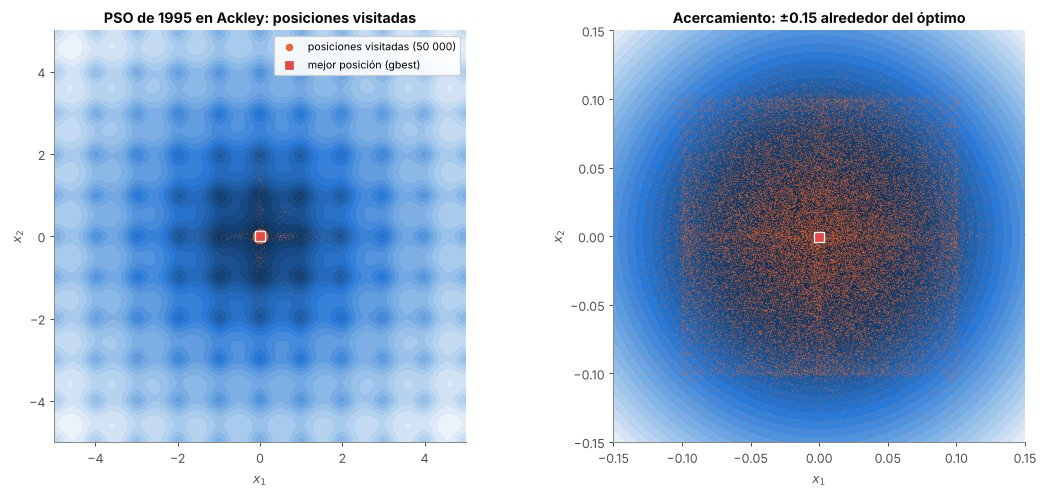

Distancia al óptimo de las posiciones en las últimas 100 generaciones: mediana 0.072, percentil 90 0.113


In [37]:
import io, contextlib

np.random.seed(0)  # semilla para reproducibilidad del notebook

fig, (ax, ax_zoom) = plt.subplots(1, 2, figsize=(12.5, 5.6))
XX, YY, ZZ = malla(ackley, -5, 5, 241)
ax.contourf(XX, YY, ZZ, levels=30, cmap=CMAP)        # paisaje de fondo
plt.sca(ax)                                           # pso() dibuja sobre los ejes actuales

salida = io.StringIO()
t0 = time.perf_counter()
with contextlib.redirect_stdout(salida):
    best = pso(max_gens, search_space, vel_space, pop_size, max_vel, c1, c2)
t_pso_ackley = time.perf_counter() - t0
lineas = salida.getvalue().splitlines()
print('\n'.join(lineas[:3] + ['   ...'] + lineas[-2:]))
print("Done.\nBest Solution: c=%g, v=%s" % (best['cost'], best['position']))
print(f'Tiempo: {t_pso_ackley:.1f} s')

# Estilo común: la nube de posiciones visitadas y la mejor posición que dibuja pso()
nube, marca = ax.get_lines()[-2:]
nube.set(marker='.', markersize=1.6, color=NARANJA, alpha=0.25, markeredgecolor='none', rasterized=True,
         label=f'posiciones visitadas ({len(nube.get_xdata()):,})'.replace(',', ' '))
marca.set(marker='s', markersize=8, markerfacecolor=OPTIMO, markeredgecolor='white', label='mejor posición (gbest)')
ax.set_aspect('equal'); ax.grid(False)
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); ax.set_title('PSO de 1995 en Ackley: posiciones visitadas')
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='none', ms=5, color=NARANJA, label=nube.get_label()),
                   Line2D([], [], marker='s', ls='none', ms=8, mfc=OPTIMO, mec='white', label=marca.get_label())],
          loc='upper right', fontsize=8.5, frameon=True, facecolor='white', framealpha=0.9)

xd, yd = np.asarray(nube.get_xdata()), np.asarray(nube.get_ydata())
Xz, Yz, Zz = malla(ackley, -0.15, 0.15, 241)
ax_zoom.contourf(Xz, Yz, Zz, levels=30, cmap=CMAP)
ax_zoom.plot(xd, yd, '.', ms=2.2, color=NARANJA, alpha=0.3, mec='none', rasterized=True)
ax_zoom.plot(*best['position'], 's', ms=8, mfc=OPTIMO, mec='white')
ax_zoom.set_xlim(-0.15, 0.15); ax_zoom.set_ylim(-0.15, 0.15)
ax_zoom.set_aspect('equal'); ax_zoom.grid(False)
ax_zoom.set_xlabel('$x_1$'); ax_zoom.set_ylabel('$x_2$'); ax_zoom.set_title('Acercamiento: ±0.15 alrededor del óptimo')
fig.tight_layout()
mostrar(fig)

dist_final = np.hypot(xd[-100 * pop_size:], yd[-100 * pop_size:])
print(f'Distancia al óptimo de las posiciones en las últimas 100 generaciones: '
      f'mediana {np.median(dist_final):.3f}, percentil 90 {np.percentile(dist_final, 90):.3f}')

**Resultado.** Con 50 000 evaluaciones el enjambre llega a $f \approx 9.9\times10^{-4}$ en $(1.6\times10^{-4},\ -3.1\times10^{-4})$. La impresión por generación cuenta la historia: en las primeras generaciones el enjambre encuentra el embudo central entre la rejilla de mínimos locales (en la generación 100 ya va en $1.3\times10^{-3}$) y después casi no mejora. El acercamiento muestra por qué: las partículas siguen oscilando dentro de un cuadrado de $\pm 0.1$ alrededor del óptimo, exactamente la velocidad máxima (la mediana de su distancia al óptimo en las últimas 100 generaciones es 0.072). Sin inercia, la velocidad nunca se amortigua: cada paso suma los tirones hacia $\mathbf{p}_i$ y $\mathbf{g}$ a la velocidad anterior completa, y solo el tope de 0.1 la contiene. El enjambre encuentra la región correcta, pero no puede asentarse.

Ese es precisamente el problema que resolvieron el **peso de inercia** $w < 1$ (Shi y Eberhart, 1998) y los coeficientes de constricción (Clerc y Kennedy, 2002): con ellos, el PSO vectorizado de la sección 4 llega a $\sim10^{-10}$ en Ackley 2D con solo 10 000 evaluaciones. La inercia es también la pieza clave del PSO para ingeniería.

### 6.2 Del PSO de Ackley al PSO para ingeniería

El programa para ingeniería conserva la estructura del de Ackley (`create_particle`, `get_global_best`, `update_velocity`, `update_position`, `update_best_position`, `pso`, partículas como diccionarios) y le agrega cuatro cosas:

1. **Restricciones $g_j(\mathbf{x}) \le 0$ con las reglas de factibilidad del artículo**: entre dos diseños factibles gana el de menor costo; entre dos no factibles, el que viola menos (suma de las violaciones); un diseño factible siempre le gana a uno no factible. No hay penalizaciones que ajustar.
2. **Variables discretas**: los espesores del recipiente se redondean a múltiplos de 0.0625 in y el número de dientes del reductor a un entero (`snap`).
3. **Velocidad máxima por variable**, igual al 20 % de su rango (las variables van de décimas a cientos de unidades, así que un solo límite como el 0.1 de Ackley no sirve).
4. **Peso de inercia** que baja en línea recta de 0.9 a 0.4 durante la corrida (Shi y Eberhart, 1998): al principio las partículas conservan su impulso y exploran; al final frenan y afinan.

Presupuesto por corrida: **40 partículas × 600 generaciones = 24 000 evaluaciones**, el mismo que usa el artículo.

*Nota de implementación: en $g_1$ del resorte usamos la constante estándar 71 785 (en la versión impresa del apéndice del artículo se lee 7,178).*

Primero, los cuatro problemas (fórmulas del apéndice del artículo):

In [38]:
import numpy as np

# ----------------------------------------------------------------------------------
# Problemas (fórmulas del apéndice del artículo)
# ----------------------------------------------------------------------------------

def welded_beam(x):
    """E01. Viga soldada: x = (h, l, t, b) = (espesor y largo de la soldadura, alto y ancho de la viga)."""
    x1, x2, x3, x4 = x
    P, L, E, G = 6000.0, 14.0, 30e6, 12e6
    cost = 1.10471 * x1**2 * x2 + 0.04811 * x3 * x4 * (14.0 + x2)
    tau_p = P / (np.sqrt(2) * x1 * x2)
    M = P * (L + x2 / 2)
    R = np.sqrt(x2**2 / 4 + ((x1 + x3) / 2)**2)
    J = 2 * (np.sqrt(2) * x1 * x2 * (x2**2 / 12 + ((x1 + x3) / 2)**2))
    tau_pp = M * R / J
    tau = np.sqrt(tau_p**2 + 2 * tau_p * tau_pp * x2 / (2 * R) + tau_pp**2)
    sigma = 6 * P * L / (x4 * x3**2)
    delta = 4 * P * L**3 / (E * x3**3 * x4)
    Pc = 4.013 * E * np.sqrt(x3**2 * x4**6 / 36) / L**2 * (1 - x3 / (2 * L) * np.sqrt(E / (4 * G)))
    g = [tau - 13600,
         sigma - 30000,
         x1 - x4,
         0.10471 * x1**2 + 0.04811 * x3 * x4 * (14 + x2) - 5.0,
         0.125 - x1,
         delta - 0.25,
         P - Pc]
    return cost, g

def pressure_vessel(x):
    """E02. Recipiente a presión: x = (Ts, Th, R, L) = espesores del casco y de las tapas, radio y largo."""
    x1, x2, x3, x4 = x
    cost = 0.6224 * x1 * x3 * x4 + 1.7781 * x2 * x3**2 + 3.1661 * x1**2 * x4 + 19.84 * x1**2 * x3
    g = [-x1 + 0.0193 * x3,
         -x2 + 0.00954 * x3,
         -np.pi * x3**2 * x4 - 4.0 / 3.0 * np.pi * x3**3 + 1296000,
         x4 - 240]
    return cost, g

def speed_reducer(x):
    """E03. Reductor de velocidad: ancho de cara, módulo, dientes del piñón, largos y diámetros de los dos ejes."""
    x1, x2, x3, x4, x5, x6, x7 = x
    weight = (0.7854 * x1 * x2**2 * (3.3333 * x3**2 + 14.9334 * x3 - 43.0934)
              - 1.508 * x1 * (x6**2 + x7**2) + 7.4777 * (x6**3 + x7**3)
              + 0.7854 * (x4 * x6**2 + x5 * x7**2))
    g = [27 / (x1 * x2**2 * x3) - 1,
         397.5 / (x1 * x2**2 * x3**2) - 1,
         1.93 * x4**3 / (x2 * x3 * x6**4) - 1,
         1.93 * x5**3 / (x2 * x3 * x7**4) - 1,
         np.sqrt((745 * x4 / (x2 * x3))**2 + 16.9e6) / (110 * x6**3) - 1,
         np.sqrt((745 * x5 / (x2 * x3))**2 + 157.5e6) / (85 * x7**3) - 1,
         x2 * x3 / 40 - 1,
         5 * x2 / x1 - 1,
         x1 / (12 * x2) - 1,
         (1.5 * x6 + 1.9) / x4 - 1,
         (1.1 * x7 + 1.9) / x5 - 1]
    return weight, g

def spring(x):
    """E04. Resorte de tensión/compresión: x = (d, D, N) = diámetro del alambre, diámetro medio y número de espiras activas."""
    x1, x2, x3 = x
    weight = (x3 + 2) * x2 * x1**2
    g = [1 - x2**3 * x3 / (71785 * x1**4),
         (4 * x2**2 - x1 * x2) / (12566 * (x2 * x1**3 - x1**4)) + 1 / (5108 * x1**2) - 1,
         1 - 140.45 * x1 / (x2**2 * x3),
         (x2 + x1) / 1.5 - 1]
    return weight, g

STEP_0625 = 0.0625
PROBLEMS = {
    'welded_beam': dict(f=welded_beam, bounds=[[0.1, 2.0], [0.1, 10.0], [0.1, 10.0], [0.1, 2.0]],
                        steps=[0, 0, 0, 0], best=1.724852),
    'pressure_vessel': dict(f=pressure_vessel, bounds=[[1 * STEP_0625, 99 * STEP_0625], [1 * STEP_0625, 99 * STEP_0625], [10.0, 200.0], [10.0, 200.0]],
                            steps=[STEP_0625, STEP_0625, 0, 0], best=6059.714335),
    'speed_reducer': dict(f=speed_reducer, bounds=[[2.6, 3.6], [0.7, 0.8], [17, 28], [7.3, 8.3], [7.8, 8.3], [2.9, 3.9], [5.0, 5.5]],
                          steps=[0, 0, 1, 0, 0, 0, 0], best=2996.348165),
    'spring': dict(f=spring, bounds=[[0.05, 2.0], [0.25, 1.3], [2.0, 15.0]],
                   steps=[0, 0, 0], best=0.012665),
}

Y el enjambre, con la misma estructura que el de Ackley:

In [39]:
# ----------------------------------------------------------------------------------
# Enjambre (misma estructura que pso_ackley.py)
# ----------------------------------------------------------------------------------

def snap(position, steps):
    """Redondea las variables discretas a su paso (0.0625 in, o 1 para enteros)."""
    for i, s in enumerate(steps):
        if s:
            position[i] = np.round(position[i] / s) * s
    return position

def objective_function(vector, problem):
    """Costo y grado de violación (suma de las restricciones que no se cumplen)."""
    cost, g = problem['f'](snap(np.copy(vector), problem['steps']))
    violation = float(sum(max(0.0, gj) for gj in g))
    return cost, violation

def better(a_cost, a_viol, b_cost, b_viol):
    """True si (a_cost, a_viol) es mejor que (b_cost, b_viol) según las reglas de factibilidad."""
    if a_viol == 0 and b_viol == 0:
        return a_cost <= b_cost
    if a_viol == 0 or b_viol == 0:
        return a_viol == 0
    return a_viol <= b_viol

def random_vector(minmax):
    #"""generate a bounded random aproximation to the solution"""
    return minmax[:, 0] + (minmax[:, 1] - minmax[:, 0]) * np.random.random(len(minmax))

def create_particle(search_space, vel_space, problem):
    #"""create a particle in a random position"""
    particle = {}
    particle['position'] = random_vector(search_space)
    particle['cost'], particle['viol'] = objective_function(particle['position'], problem)
    particle['b_position'] = np.copy(particle['position'])
    particle['b_cost'], particle['b_viol'] = particle['cost'], particle['viol']
    particle['velocity'] = random_vector(vel_space)
    return particle

def get_global_best(population, current_best=None):
    #"""get the best global particle (con las reglas de factibilidad)"""
    population.sort(key=lambda p: (p['viol'] > 0, p['viol'] if p['viol'] > 0 else p['cost']))
    best = population[0]
    if current_best is None or better(best['cost'], best['viol'], current_best['cost'], current_best['viol']):
        current_best = {}
        current_best['position'] = np.copy(best['position'])
        current_best['cost'] = best['cost']
        current_best['viol'] = best['viol']
    return current_best

def update_velocity(particle, gbest, max_v, c1, c2, w=1.0):
    for i, v in enumerate(particle['velocity']):
        v1 = c1 * np.random.random() * (particle['b_position'][i] - particle['position'][i])
        v2 = c2 * np.random.random() * (gbest['position'][i] - particle['position'][i])
        particle['velocity'][i] = w * v + v1 + v2
        if particle['velocity'][i] > max_v[i]: particle['velocity'][i] = max_v[i]
        if particle['velocity'][i] < -max_v[i]: particle['velocity'][i] = -max_v[i]

def update_position(part, bounds):
    #"""update the position of a particle"""
    for i, v in enumerate(part['position']):
        part['position'][i] = v + part['velocity'][i]
        if part['position'][i] > bounds[i][1]:
            part['position'][i] = bounds[i][1] - abs(part['position'][i] - bounds[i][1])
            part['velocity'][i] *= -1.0
        elif part['position'][i] < bounds[i][0]:
            part['position'][i] = bounds[i][0] + abs(part['position'][i] - bounds[i][0])
            part['velocity'][i] *= -1.0
        part['position'][i] = min(max(part['position'][i], bounds[i][0]), bounds[i][1])

def update_best_position(particle):
    #"""update the best position of a particle"""
    if better(particle['cost'], particle['viol'], particle['b_cost'], particle['b_viol']):
        particle['b_cost'], particle['b_viol'] = particle['cost'], particle['viol']
        particle['b_position'] = np.copy(particle['position'])

def pso(problem, max_gens=600, pop_size=40, vel_frac=0.2, c1=2.0, c2=2.0, w=(0.9, 0.4), verbose=False):
    #"""implements the Particle Swarm Optimization Algorithm"""
    # w puede ser un número o una pareja (inicial, final): la inercia baja en línea recta
    w0, w1 = (w, w) if np.isscalar(w) else w
    search_space = np.array(problem['bounds'], float)
    width = search_space[:, 1] - search_space[:, 0]
    max_vel = vel_frac * width
    vel_space = np.stack([-max_vel, max_vel], axis=1)
    pop = [create_particle(search_space, vel_space, problem) for _ in range(pop_size)]
    gbest = get_global_best(pop)
    history = [gbest['cost'] if gbest['viol'] == 0 else np.nan]
    for gen in range(max_gens):
        w_gen = w0 + (w1 - w0) * gen / max(1, max_gens - 1)
        for i, particle in enumerate(pop):
            update_velocity(particle, gbest, max_vel, c1, c2, w_gen)
            update_position(particle, search_space)
            particle['cost'], particle['viol'] = objective_function(particle['position'], problem)
            update_best_position(particle)
            pop[i] = particle
        gbest = get_global_best(pop, gbest)
        history.append(gbest['cost'] if gbest['viol'] == 0 else np.nan)
        if verbose:
            print(" > gen=%d, cost=%g, violation=%g" % (gen + 1, gbest['cost'], gbest['viol']))
    gbest['position'] = snap(gbest['position'], problem['steps'])
    gbest['history'] = np.array(history)
    return gbest

### 6.3 Experimento: 30 corridas por problema

Como en el artículo, 30 corridas independientes por problema, cada una con `np.random.seed(s)`, $s = 0, \dots, 29$, y la configuración por defecto. Esta celda es la más lenta del notebook (el PSO está escrito con ciclos de Python, partícula por partícula).

In [40]:
NOMBRES_ING = {'welded_beam': 'Viga soldada', 'pressure_vessel': 'Recipiente a presión',
               'speed_reducer': 'Reductor de velocidad', 'spring': 'Resorte'}

corridas_ing = {}
t0 = time.perf_counter()
for nombre, problema in PROBLEMS.items():
    corridas_ing[nombre] = []
    for s in range(30):
        np.random.seed(s)
        corridas_ing[nombre].append(pso(problema))
print(f'120 corridas en {time.perf_counter() - t0:.1f} s')

filas = []
for nombre, res in corridas_ing.items():
    costos = np.array([r['cost'] for r in res])
    viol = np.array([r['viol'] for r in res])
    filas.append({'problema': NOMBRES_ING[nombre],
                  'mejor': f'{costos.min():.6f}', 'media': f'{costos.mean():.6f}',
                  'mediana': f'{np.median(costos):.6f}', 'desv. est.': f'{costos.std():.2g}',
                  'peor': f'{costos.max():.6f}', 'corridas factibles': f'{(viol == 0).sum()}/30',
                  'mejor conocido': f"{PROBLEMS[nombre]['best']:.6f}"})
resumen_ing = pd.DataFrame(filas).set_index('problema')
resumen_ing

120 corridas en 52.4 s


,mejor,media,mediana,desv. est.,peor,corridas factibles,mejor conocido
problema,,,,,,,
Viga soldada,1.724852,1.725181,1.724854,0.0011,1.730857,30/30,1.724852
Recipiente a presión,6059.714343,6327.897017,6370.779729,2.5e+02,6820.410115,30/30,6059.714335
Reductor de velocidad,2996.348165,2996.348165,2996.348165,1.2e-07,2996.348165,30/30,2996.348165
Resorte,0.012667,0.012993,0.012956,0.0003,0.013990,30/30,0.012665


**¿Por qué la inercia?** Repetimos las primeras 8 semillas con $w = 1$ (la velocidad anterior se conserva completa, como en el PSO de Ackley) y comparamos medianas con las mismas 8 semillas de la configuración por defecto:

In [41]:
filas = []
t0 = time.perf_counter()
for nombre, problema in PROBLEMS.items():
    sin_inercia = []
    for s in range(8):
        np.random.seed(s)
        sin_inercia.append(pso(problema, w=1.0)['cost'])
    con_inercia = [r['cost'] for r in corridas_ing[nombre][:8]]
    filas.append({'problema': NOMBRES_ING[nombre],
                  'mediana con w = 1': f'{np.median(sin_inercia):.6g}',
                  'mediana con w de 0.9 a 0.4': f'{np.median(con_inercia):.6g}',
                  'mejor conocido': f"{PROBLEMS[nombre]['best']:.6g}"})
print(f'32 corridas en {time.perf_counter() - t0:.1f} s')
pd.DataFrame(filas).set_index('problema')

32 corridas en 13.4 s


,mediana con w = 1,mediana con w de 0.9 a 0.4,mejor conocido
problema,,,
Viga soldada,1.81161,1.72486,1.72485
Recipiente a presión,6799.59,6390.43,6059.71
Reductor de velocidad,3025.58,2996.35,2996.35
Resorte,0.0140868,0.0130562,0.012665


Sin inercia, las medianas quedan lejos del mejor conocido en los cuatro problemas: 1.812 en la viga (+5 %), 6 799.6 en el recipiente (+12 %), 3 025.6 en el reductor (+1 %) y 0.01409 en el resorte (+11 %). Con la inercia decreciente, la viga y el reductor llegan al mejor conocido, y el recipiente y el resorte se acercan mucho más (6 390.4 y 0.01306). La razón es la misma que en Ackley: sin un factor que frene la velocidad, el enjambre explora bien pero no logra afinar.

### 6.4 Comparación con el artículo

Los valores de SiC-PSO (el algoritmo del artículo), COPSO (Hernández Aguirre et al.) y Mezura (evolución diferencial de Mezura y Coello) son los de las Tablas 1 y 2 de Cagnina, Esquivel y Coello Coello (2008). Nuestro PSO y SiC-PSO usan 24 000 evaluaciones por corrida; COPSO y Mezura, 30 000.

In [42]:
ARTICULO = {   # Tablas 1 y 2 del artículo; '*' = solución no factible según el artículo
    'welded_beam':     dict(mejor=['1.724852', '1.724852', '1.724852'], media=['2.0574', '1.7248', '1.7776'],
                            desv=['0.2154', '1.2E-05', '8.8E-02']),
    'pressure_vessel': dict(mejor=['6059.714335', '6059.714335', '6059.7143'], media=['6092.0498', '6071.0133', '6379.9380'],
                            desv=['12.1725', '15.1011', '210.0000']),
    'speed_reducer':   dict(mejor=['2996.348165', '2996.372448', '2996.348094*'], media=['2996.3482', '2996.4085', '2996.3480*'],
                            desv=['0.0000', '0.0286', '0.0000*']),
    'spring':          dict(mejor=['0.012665', '0.012665', '0.012689'], media=['0.0131', '0.0126', '0.0131'],
                            desv=['4.1E-04', '1.2E-06', '3.9E-04']),
}
filas = []
for nombre, res in corridas_ing.items():
    costos = np.array([r['cost'] for r in res])
    nuestro = {'mejor': f'{costos.min():.6f}', 'media': f'{costos.mean():.6f}', 'desv': f'{costos.std():.2g}'}
    for medida, etiqueta in (('mejor', 'mejor'), ('media', 'media'), ('desv', 'desv. est.')):
        filas.append({'problema': NOMBRES_ING[nombre], 'medida': etiqueta, 'nuestro PSO': nuestro[medida],
                      **dict(zip(['SiC-PSO', 'COPSO', 'Mezura'], ARTICULO[nombre][medida]))})
comparacion_ing = pd.DataFrame(filas).set_index(['problema', 'medida'])
print('* solución no factible según el artículo')
comparacion_ing

* solución no factible según el artículo


nuestro PSO      SiC-PSO        COPSO        Mezura
problema              medida                                                         
Viga soldada          mejor          1.724852     1.724852     1.724852      1.724852
                      media          1.725181       2.0574       1.7248        1.7776
                      desv. est.       0.0011       0.2154      1.2E-05       8.8E-02
Recipiente a presión  mejor       6059.714343  6059.714335  6059.714335     6059.7143
                      media       6327.897017    6092.0498    6071.0133     6379.9380
                      desv. est.      2.5e+02      12.1725      15.1011      210.0000
Reductor de velocidad mejor       2996.348165  2996.348165  2996.372448  2996.348094*
                      media       2996.348165    2996.3482    2996.4085    2996.3480*
                      desv. est.      1.2e-07       0.0000       0.0286       0.0000*
Resorte               mejor          0.012667     0.012665     0.012665      0.012689
                      media          0.012993       0.0131       0.0126        0.0131
                      desv. est.       0.0003      4.1E-04      1.2E-06       3.9E-04

* **Mejor diseño**: igualamos el mejor diseño conocido en los cuatro problemas. En el recipiente la diferencia está en la sexta cifra decimal (6059.714343 frente a 6059.714335, por el redondeo de las variables continuas) y en el resorte quedamos a 0.01 % (0.012667 frente a 0.012665).
* **Media**: en la viga (1.725181) y en el reductor (2996.348165) prácticamente todas las corridas terminan en el óptimo. En la viga la media es mejor que la de SiC-PSO (2.0574) y Mezura (1.7776) y muy cercana a la de COPSO (1.7248); en el reductor es igual a la de SiC-PSO y mejor que la de COPSO (la de Mezura está marcada como no factible en el artículo). En el resorte (0.012993) quedamos mejor que SiC-PSO y Mezura (0.0131) y por encima de COPSO (0.0126).
* **El recipiente es el caso difícil**: media de 6 327.9 con desviación de 252, frente a 6 092.0 de SiC-PSO y 6 071.0 de COPSO; solo Mezura (6 379.9) queda por encima. La sección 6.6 explica por qué.
* Todo esto con un PSO global clásico, sin las ideas más elaboradas de SiC-PSO (vecindarios en anillo y actualización gaussiana de la posición), y con el mismo presupuesto de 24 000 evaluaciones.

### 6.5 Los cuatro problemas y sus mejores diseños

Para cada problema: la formulación, las variables, un esquema a escala del mejor diseño que encontró nuestro PSO en las 30 corridas y el valor de cada restricción en ese diseño. Una restricción está **activa** cuando el diseño queda justo en su límite ($g_j \approx 0$); para decidirlo, dividimos $g_j$ entre una escala natural (el límite de esfuerzo, el volumen mínimo, …) y la consideramos activa si el cociente es mayor que $-10^{-3}$.

In [43]:
from matplotlib.patches import Rectangle, Polygon, Circle

ACERO, ACERO_BORDE, SOLDADURA = '#c9d6e6', '#134074', '#eb6834'

def _cota(ax, p0, p1, texto, desplaz=(0, 0), color=TINTA_2, fs=9, **kw):
    ax.annotate('', xy=p1, xytext=p0, arrowprops=dict(arrowstyle='<->', color=color, lw=1))
    mx, my = (p0[0] + p1[0]) / 2 + desplaz[0], (p0[1] + p1[1]) / 2 + desplaz[1]
    ax.text(mx, my, texto, ha='center', va='center', fontsize=fs, color=TINTA, **kw)

def _limpio(ax, titulo):
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(titulo)

def esquema_viga(x, ax=None):
    h, l, t, b = x
    L = 14.0
    ax = ax or plt.gca()
    # soporte (miembro B)
    ax.add_patch(Rectangle((-2.0, -t / 2 - 3), 2.0, t + 6, fc='#e6e5e1', ec=GRIS, hatch='///', lw=1))
    # viga (miembro A)
    ax.add_patch(Rectangle((0, -t / 2), l + L, t, fc=ACERO, ec=ACERO_BORDE, lw=1.4))
    # cordones de soldadura arriba y abajo (vista lateral: triángulos de cateto h, exagerados x3 para que se vean)
    hv = 3 * h
    for s in (+1, -1):
        y0 = s * t / 2
        ax.add_patch(Polygon([(0, y0), (l, y0), (0, y0 + s * hv)], closed=True, fc=SOLDADURA, ec=SOLDADURA))
    # carga P
    ax.annotate('', xy=(l + L, t / 2), xytext=(l + L, t / 2 + 4.5),
                arrowprops=dict(arrowstyle='-|>', color=TINTA, lw=1.8, mutation_scale=16))
    ax.text(l + L + 0.4, t / 2 + 3.3, 'P = 6 000 lb', fontsize=9, color=TINTA)
    _cota(ax, (0, -t / 2 - 1.2), (l, -t / 2 - 1.2), f'l = {l:.3f}', (0, -0.8))
    _cota(ax, (l, -t / 2 - 1.2), (l + L, -t / 2 - 1.2), 'L = 14', (0, -0.8))
    _cota(ax, (l + L + 1.0, -t / 2), (l + L + 1.0, t / 2), f't = {t:.3f}', (1.6, 0))
    ax.annotate(f'h = {h:.4f}\n(soldadura, exagerada ×3)', xy=(l * 0.3, t / 2 + hv * 0.4), xytext=(l + 2.0, t / 2 + 2.6),
                fontsize=9, color=TINTA, arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8))
    ax.text((l + L) / 2 + 1, 0, f'viga: ancho b = {b:.4f}', ha='center', va='center', fontsize=9, color=ACERO_BORDE)
    ax.text(-1.0, -t / 2 - 3.6, 'soporte', ha='center', va='top', fontsize=8.5, color=TINTA_2)
    ax.set_xlim(-2.5, l + L + 5); ax.set_ylim(-t / 2 - 4.2, t / 2 + 5.2)
    _limpio(ax, 'Viga soldada (vista lateral, a escala salvo la soldadura)')

def esquema_recipiente(x, ax=None, exagera=4.0):
    Ts, Th, R, L = x
    ax = ax or plt.gca()
    ts, th = exagera * Ts, exagera * Th
    th_ang = np.linspace(np.pi / 2, 3 * np.pi / 2, 120)
    def contorno(Rc, ec_izq, ec_der):
        # cilindro de 0 a L, tapas semiesféricas (vista lateral = semicírculos)
        izq = np.c_[ec_izq * 0 + Rc * np.cos(th_ang), Rc * np.sin(th_ang)]
        der = np.c_[L - Rc * np.cos(th_ang), -Rc * np.sin(th_ang)]
        return np.vstack([izq, der])
    # pared: exterior relleno de acero, interior en blanco
    ext_izq = np.c_[(R + th) * np.cos(th_ang), (R + th) * np.sin(th_ang)]
    ext_der = np.c_[L - (R + th) * np.cos(th_ang), -(R + th) * np.sin(th_ang)]
    ax.add_patch(Polygon(np.vstack([ext_izq, ext_der]), closed=True, fc=ACERO, ec=ACERO_BORDE, lw=1.2))
    ax.add_patch(Rectangle((0, -(R + ts)), L, 2 * (R + ts), fc=ACERO, ec='none'))
    ax.plot([0, L], [R + ts, R + ts], color=ACERO_BORDE, lw=1.2); ax.plot([0, L], [-(R + ts), -(R + ts)], color=ACERO_BORDE, lw=1.2)
    ax.add_patch(Polygon(contorno(R, 0, 0), closed=True, fc='white', ec=ACERO_BORDE, lw=1.0))
    # uniones casco-tapa
    for xc in (0, L):
        ax.plot([xc, xc], [-(R + max(ts, th)), R + max(ts, th)], color=GRIS, lw=0.8, ls=':')
    _cota(ax, (0, 0), (L, 0), f'L = {L:.2f}', (0, 4))
    _cota(ax, (0.78 * L, 0), (0.78 * L, R), f'R = {R:.2f}', (12, 0))
    ax.annotate(f'casco $T_s$ = {Ts:.4f}', xy=(L * 0.3, R + ts / 2), xytext=(L * 0.12, R + 22), fontsize=9,
                arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8))
    ax.annotate(f'tapa $T_h$ = {Th:.4f}', xy=(L + R * np.cos(np.pi / 4) + th / 2, R * np.sin(np.pi / 4)), xytext=(L + 6, R + 22),
                fontsize=9, arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8))
    ax.text(L / 2, -R / 2, 'aire comprimido a 3 000 psi\nvolumen ≥ 750 ft³', ha='center', va='center', fontsize=9, color=TINTA_2)
    ax.set_xlim(-R - 12, L + R + 12); ax.set_ylim(-R - 12, R + 30)
    _limpio(ax, f'Recipiente a presión (a escala; espesores exagerados ×{exagera:g})')

def esquema_resorte(x, ax=None, paso=None):
    d, D, N = x
    ax = ax or plt.gca()
    n_total = N + 2                      # espiras activas + 2 de los extremos
    paso = paso or 3.6 * d
    largo = paso * n_total
    ax.set_xlim(-0.75, largo + 0.6); ax.set_ylim(-D / 2 - 0.35, D / 2 + 0.35); ax.set_aspect('equal')
    ax.apply_aspect()
    # grosor de línea = diámetro real del alambre (puntos por unidad de datos)
    pts_por_unidad = (ax.transData.transform((1, 0))[0] - ax.transData.transform((0, 0))[0]) * 72 / ax.figure.dpi
    lw = d * pts_por_unidad
    t = np.linspace(0, 2 * np.pi * n_total, int(400 * n_total))
    xs = paso * t / (2 * np.pi)
    ys = (D / 2) * np.cos(t)
    frente = np.sin(t) >= 0
    for mascara, color, z in ((~frente, '#8fbbe8', 1), (frente, ACERO_BORDE, 2)):
        ax.plot(xs, np.where(mascara, ys, np.nan), color=color, lw=lw, solid_capstyle='round', zorder=z)
    _cota(ax, (-0.1, -D / 2), (-0.1, D / 2), '', (0, 0))
    ax.text(-0.14, 0, f'D = {D:.4f}', ha='right', va='center', fontsize=9)
    ax.annotate(f'd = {d:.5f} (alambre)', xy=(paso * 0.5, D / 2), xytext=(paso * 2.0, D / 2 + 0.2), fontsize=9,
                arrowprops=dict(arrowstyle='-', color=TINTA_2, lw=0.8))
    ax.text(largo / 2, -D / 2 - 0.1, f'N = {N:.3f} espiras activas (+ 2 en los extremos)', ha='center', va='top', fontsize=9)
    ax.annotate('', xy=(largo + 0.03, 0), xytext=(largo + 0.5, 0), arrowprops=dict(arrowstyle='-|>', color=TINTA, lw=1.4))
    ax.text(largo + 0.3, 0.06, 'F', fontsize=10)
    ax.axis('off'); ax.set_title('Resorte helicoidal (a escala; el paso entre espiras es ilustrativo)')

def _engrane(ax, cx, cy, z, m, color, ec, rot=0.0):
    r = m * z / 2; ra, rf = r + m, r - 1.25 * m
    pts = []
    for k in range(z):
        a0 = rot + 2 * np.pi * k / z
        for frac, rr in ((0.0, rf), (0.12, rf), (0.27, ra), (0.48, ra), (0.63, rf), (1.0, rf)):
            a = a0 + frac * 2 * np.pi / z
            pts.append((cx + rr * np.cos(a), cy + rr * np.sin(a)))
    ax.add_patch(Polygon(pts, closed=True, fc=color, ec=ec, lw=0.8))
    return r

def esquema_reductor(x, axs=None, razon=2.5):
    b, m, z, l1, l2, d1, d2 = x
    z = int(round(z))
    if axs is None:
        fig, axs = plt.subplots(1, 2, figsize=(12, 4.8))
    ax1, ax2 = axs
    # Vista frontal: piñón con z dientes y engrane mayor (esquemático)
    rp = m * z / 2; zg = int(round(razon * z)); rg = m * zg / 2
    _engrane(ax1, 0, 0, z, m, ACERO, ACERO_BORDE)
    _engrane(ax1, rp + rg, 0, zg, m, '#e6e5e1', GRIS, rot=np.pi / zg)
    ax1.add_patch(Circle((0, 0), d1 / 2, fc='white', ec=ACERO_BORDE, lw=1.2))
    ax1.add_patch(Circle((rp + rg, 0), d2 / 2, fc='white', ec=GRIS, lw=1.2))
    ax1.text(0, -rp - 2.2, f'piñón: z = {z} dientes,\nmódulo m = {m:.3f}', ha='center', va='top', fontsize=9)
    ax1.text(rp + rg, -rg - 1.2, 'engrane conducido\n(tamaño esquemático)', ha='center', va='top', fontsize=9, color=TINTA_2)
    ax1.set_xlim(-rp - 3, rp + 2 * rg + 3); ax1.set_ylim(-rg - 6, rg + 3)
    _limpio(ax1, 'Vista frontal')
    # Vista lateral de los ejes, a escala (el eje 2 se dibuja debajo, sin su engrane)
    y2 = -rp - 4.5 - d2 / 2
    for (y, L_, d_, col) in ((0, l1, d1, ACERO_BORDE), (y2, l2, d2, GRIS)):
        ax2.add_patch(Rectangle((-L_ / 2 - 1.5, y - d_ / 2), L_ + 3, d_, fc='white', ec=col, lw=1.2))
        for xb in (-L_ / 2, L_ / 2):
            ax2.add_patch(Rectangle((xb - 0.45, y - d_ / 2 - 0.6), 0.9, d_ + 1.2, fc='#e6e5e1', ec=GRIS, hatch='////', lw=0.8))
    ax2.add_patch(Rectangle((-b / 2, -rp), b, 2 * rp, fc=ACERO, ec=ACERO_BORDE, lw=1.2))
    ax2.text(0, rp + 0.6, f'eje 1: $l_1$ = {l1:.3f} entre cojinetes, $d_1$ = {d1:.3f}', ha='center', va='bottom', fontsize=9)
    ax2.text(0, y2 - d2 / 2 - 1.0, f'eje 2: $l_2$ = {l2:.3f} entre cojinetes, $d_2$ = {d2:.3f}', ha='center', va='top', fontsize=9)
    _cota(ax2, (-b / 2, -rp - 0.9), (b / 2, -rp - 0.9), '')
    ax2.text(b / 2 + 0.4, -rp - 0.9, f'b = {b:.3f}', ha='left', va='center', fontsize=9)
    ax2.text(0, rp * 0.6, 'piñón', ha='center', va='center', fontsize=9, color=ACERO_BORDE)
    ax2.set_xlim(-l2 / 2 - 4, l2 / 2 + 4); ax2.set_ylim(y2 - d2 / 2 - 3, rp + 2.5)
    _limpio(ax2, 'Ejes y piñón (vista lateral, a escala)')
    return axs


DESCRIPCION_G = {
    'welded_beam': ['esfuerzo cortante en la soldadura τ ≤ 13 600 psi', 'esfuerzo de flexión en la viga σ ≤ 30 000 psi',
                    'la soldadura no es más gruesa que la viga (h ≤ b)', 'límite de costo de material',
                    'espesor mínimo de soldadura h ≥ 0.125 in', 'deflexión en el extremo δ ≤ 0.25 in',
                    'carga de pandeo P_c ≥ P = 6 000 lb'],
    'pressure_vessel': ['espesor mínimo del casco T_s ≥ 0.0193 R', 'espesor mínimo de las tapas T_h ≥ 0.00954 R',
                        'volumen mínimo de 750 ft³ (1 296 000 in³)', 'largo máximo L ≤ 240 in'],
    'speed_reducer': ['esfuerzo de flexión en los dientes', 'esfuerzo de contacto en los dientes',
                      'deflexión transversal del eje 1', 'deflexión transversal del eje 2',
                      'esfuerzo en el eje 1', 'esfuerzo en el eje 2', 'tamaño del piñón (m·z ≤ 40)',
                      'ancho de cara b ≥ 5 m', 'ancho de cara b ≤ 12 m',
                      'largo del eje 1: l₁ ≥ 1.5 d₁ + 1.9', 'largo del eje 2: l₂ ≥ 1.1 d₂ + 1.9'],
    'spring': ['deflexión mínima', 'esfuerzo cortante', 'frecuencia de oscilación (surge)',
               'diámetro exterior D + d ≤ 1.5'],
}
ESCALA_G = {'welded_beam': [13600, 30000, 1, 5, 1, 0.25, 6000], 'pressure_vessel': [1, 1, 1296000, 240],
            'speed_reducer': [1] * 11, 'spring': [1] * 4}
VARIABLES = {
    'welded_beam': ['h: espesor de la soldadura', 'l: largo de la soldadura', 't: alto de la viga', 'b: ancho de la viga'],
    'pressure_vessel': ['T_s: espesor del casco', 'T_h: espesor de las tapas', 'R: radio interior', 'L: largo del cilindro'],
    'speed_reducer': ['b: ancho de cara', 'm: módulo de los dientes', 'z: dientes del piñón', 'l₁: largo del eje 1',
                      'l₂: largo del eje 2', 'd₁: diámetro del eje 1', 'd₂: diámetro del eje 2'],
    'spring': ['d: diámetro del alambre', 'D: diámetro medio de la espira', 'N: espiras activas'],
}
X_ARTICULO = {'welded_beam': [0.205730, 3.470489, 9.036624, 0.205729],
              'pressure_vessel': [0.8125, 0.4375, 42.098446, 176.636596],
              'speed_reducer': [3.5, 0.7, 17, 7.3, 7.8, 3.350214, 5.286683],
              'spring': [0.051690, 0.356750, 11.287126]}


def mejor_corrida(nombre):
    return min(corridas_ing[nombre], key=lambda r: (r['viol'] > 0, r['cost']))


def tabla_diseno(nombre):
    x = mejor_corrida(nombre)['position']
    return pd.DataFrame({'variable': VARIABLES[nombre], 'nuestro PSO': [f'{v:.6f}' for v in x],
                         'mejor conocido (artículo)': [f'{v:.6f}' for v in X_ARTICULO[nombre]]}).set_index('variable')


def tabla_restricciones(nombre):
    r = mejor_corrida(nombre)
    costo, g = PROBLEMS[nombre]['f'](r['position'])
    g = np.array(g, dtype=float)
    norm = g / np.array(ESCALA_G[nombre], dtype=float)
    print(f"{NOMBRES_ING[nombre]}: costo del mejor diseño = {costo:.6f} (mejor conocido {PROBLEMS[nombre]['best']:.6f}); "
          f"restricciones activas: {int((norm > -1e-3).sum())} de {len(g)}")
    return pd.DataFrame({'restricción': [f'g{j + 1}' for j in range(len(g))], 'qué limita': DESCRIPCION_G[nombre],
                         'g_j(x)': [f'{v:.3e}' for v in g], 'g_j / escala': [f'{v:.2e}' for v in norm],
                         'estado': ['activa' if v > -1e-3 else 'holgada' for v in norm]}).set_index('restricción')

#### Viga soldada (E01)

Una viga en voladizo se suelda a un soporte y carga $P = 6\,000$ lb en su extremo. Se busca el **costo mínimo de fabricación** (soldadura más material).

$$
\min_{\mathbf{x}}\; f(\mathbf{x}) = 1.10471\,x_1^2 x_2 + 0.04811\,x_3 x_4\,(14 + x_2)
$$

$$
\begin{aligned}
g_1 &= \tau(\mathbf{x}) - 13\,600 \le 0, & g_5 &= 0.125 - x_1 \le 0,\\
g_2 &= \sigma(\mathbf{x}) - 30\,000 \le 0, & g_6 &= \delta(\mathbf{x}) - 0.25 \le 0,\\
g_3 &= x_1 - x_4 \le 0, & g_7 &= P - P_c(\mathbf{x}) \le 0,\\
g_4 &= 0.10471\,x_1^2 + 0.04811\,x_3 x_4\,(14 + x_2) - 5 \le 0, &&
\end{aligned}
$$

con

$$
\tau = \sqrt{\tau'^2 + 2\tau'\tau''\frac{x_2}{2R} + \tau''^2},\quad
\tau' = \frac{P}{\sqrt{2}\,x_1 x_2},\quad
\tau'' = \frac{MR}{J},\quad
M = P\left(L + \frac{x_2}{2}\right),\quad
R = \sqrt{\frac{x_2^2}{4} + \left(\frac{x_1 + x_3}{2}\right)^2},
$$

$$
J = 2\left\{\sqrt{2}\,x_1 x_2\left[\frac{x_2^2}{12} + \left(\frac{x_1 + x_3}{2}\right)^2\right]\right\},\quad
\sigma = \frac{6PL}{x_4 x_3^2},\quad
\delta = \frac{4PL^3}{E\,x_3^3 x_4},\quad
P_c = \frac{4.013\,E\sqrt{x_3^2 x_4^6/36}}{L^2}\left(1 - \frac{x_3}{2L}\sqrt{\frac{E}{4G}}\right),
$$

$L = 14$ in, $E = 30\times10^6$ psi, $G = 12\times10^6$ psi.

| Variable | Significado | Rango (in) |
|---|---|---|
| $x_1 = h$ | espesor del cordón de soldadura | $[0.1, 2]$ |
| $x_2 = l$ | largo de la soldadura | $[0.1, 10]$ |
| $x_3 = t$ | alto de la viga | $[0.1, 10]$ |
| $x_4 = b$ | ancho de la viga | $[0.1, 2]$ |

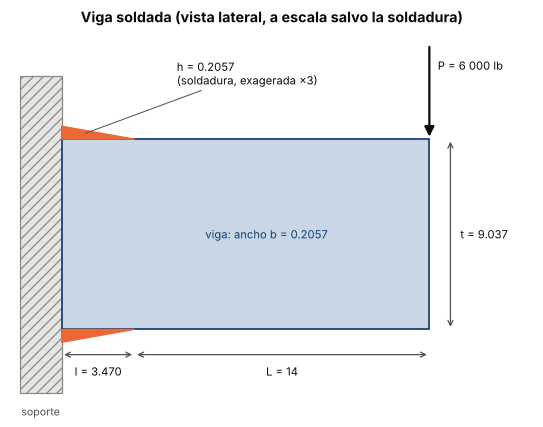

,nuestro PSO,mejor conocido (artículo)
variable,,
h: espesor de la soldadura,0.205730,0.205730
l: largo de la soldadura,3.470489,3.470489
t: alto de la viga,9.036624,9.036624
b: ancho de la viga,0.205730,0.205729


Viga soldada: costo del mejor diseño = 1.724852 (mejor conocido 1.724852); restricciones activas: 4 de 7


,qué limita,g_j(x),g_j / escala,estado
restricción,,,,
g1,esfuerzo cortante en la soldadura τ ≤ 13 600 psi,-7.107e-05,-5.23e-09,activa
g2,esfuerzo de flexión en la viga σ ≤ 30 000 psi,-5.254e-04,-1.75e-08,activa
g3,la soldadura no es más gruesa que la viga (h ≤ b),-9.552e-10,-9.55e-10,activa
g4,límite de costo de material,-3.433e+00,-6.87e-01,holgada
g5,espesor mínimo de soldadura h ≥ 0.125 in,-8.073e-02,-8.07e-02,holgada
g6,deflexión en el extremo δ ≤ 0.25 in,-2.355e-01,-9.42e-01,holgada
g7,carga de pandeo P_c ≥ P = 6 000 lb,-1.005e-04,-1.67e-08,activa


In [44]:
fig, ax = plt.subplots(figsize=(9.5, 5.6))
esquema_viga(mejor_corrida('welded_beam')['position'], ax)
plt.show()
display(tabla_diseno('welded_beam'))
tabla_restricciones('welded_beam')

Nuestro mejor diseño coincide con el del artículo hasta la sexta cifra decimal. Quedan activas cuatro restricciones: el esfuerzo cortante en la soldadura ($g_1$), el esfuerzo de flexión ($g_2$), la condición $h \le b$ ($g_3$: la soldadura es exactamente tan gruesa como ancha es la viga) y la carga de pandeo ($g_7$). El óptimo no está en el fondo de un valle sino en una esquina donde se cruzan varios límites, y las reglas de factibilidad son las que llevan al enjambre hasta ahí.

#### Recipiente a presión (E02)

Un tanque de aire comprimido a 3 000 psi con volumen mínimo de 750 ft³: un cilindro cerrado por dos tapas semiesféricas, hecho con placa de acero rolada. Se minimiza el **costo total de material, conformado y soldadura**.

$$
\min_{\mathbf{x}}\; f(\mathbf{x}) = 0.6224\,x_1 x_3 x_4 + 1.7781\,x_2 x_3^2 + 3.1661\,x_1^2 x_4 + 19.84\,x_1^2 x_3
$$

$$
\begin{aligned}
g_1 &= -x_1 + 0.0193\,x_3 \le 0, & g_3 &= -\pi x_3^2 x_4 - \tfrac{4}{3}\pi x_3^3 + 1\,296\,000 \le 0,\\
g_2 &= -x_2 + 0.00954\,x_3 \le 0, & g_4 &= x_4 - 240 \le 0.
\end{aligned}
$$

| Variable | Significado | Rango (in) |
|---|---|---|
| $x_1 = T_s$ | espesor del casco (múltiplo de 0.0625) | $[0.0625,\ 99 \times 0.0625]$ |
| $x_2 = T_h$ | espesor de las tapas (múltiplo de 0.0625) | $[0.0625,\ 99 \times 0.0625]$ |
| $x_3 = R$ | radio interior | $[10, 200]$ |
| $x_4 = L$ | largo de la sección cilíndrica | $[10, 200]$ |

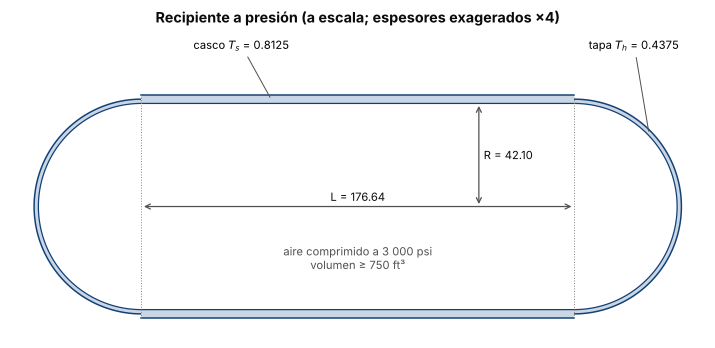

,nuestro PSO,mejor conocido (artículo)
variable,,
T_s: espesor del casco,0.812500,0.812500
T_h: espesor de las tapas,0.437500,0.437500
R: radio interior,42.098446,42.098446
L: largo del cilindro,176.636597,176.636596


Recipiente a presión: costo del mejor diseño = 6059.714343 (mejor conocido 6059.714335); restricciones activas: 2 de 4


,qué limita,g_j(x),g_j / escala,estado
restricción,,,,
g1,espesor mínimo del casco T_s ≥ 0.0193 R,-1.174e-09,-1.17e-09,activa
g2,espesor mínimo de las tapas T_h ≥ 0.00954 R,-3.588e-02,-3.59e-02,holgada
g3,volumen mínimo de 750 ft³ (1 296 000 in³),-1.002e-04,-7.73e-11,activa
g4,largo máximo L ≤ 240 in,-6.336e+01,-2.64e-01,holgada


In [45]:
fig, ax = plt.subplots(figsize=(10, 4.8))
esquema_recipiente(mejor_corrida('pressure_vessel')['position'], ax)
plt.show()
display(tabla_diseno('pressure_vessel'))
tabla_restricciones('pressure_vessel')

Coincide con el mejor diseño conocido: $T_s = 0.8125$ y $T_h = 0.4375$ (13 y 7 veces 0.0625 in), $R = 42.098$ y $L = 176.637$. Quedan activos el espesor mínimo del casco ($g_1$: $R$ es justo el mayor radio que permite $T_s$) y el volumen mínimo ($g_3$). El espesor de las tapas queda holgado porque solo puede tomar múltiplos de 0.0625: el mínimo exigido, $0.00954\,R = 0.4016$, se redondea hacia arriba a 0.4375.

#### Reductor de velocidad (E03)

El reductor de Golinski (1973): un par de engranes (piñón y engrane conducido) montados en dos ejes paralelos. Se minimiza el **peso** sujeto a límites de esfuerzo en los dientes, deflexión y esfuerzo de los ejes, y reglas de proporción de diseño.

$$
\begin{aligned}
\min_{\mathbf{x}}\; f(\mathbf{x}) ={}& 0.7854\,x_1 x_2^2\,(3.3333\,x_3^2 + 14.9334\,x_3 - 43.0934) - 1.508\,x_1\,(x_6^2 + x_7^2)\\
&+ 7.4777\,(x_6^3 + x_7^3) + 0.7854\,(x_4 x_6^2 + x_5 x_7^2)
\end{aligned}
$$

$$
\begin{aligned}
g_1 &= \frac{27}{x_1 x_2^2 x_3} - 1 \le 0, &
g_2 &= \frac{397.5}{x_1 x_2^2 x_3^2} - 1 \le 0, &
g_3 &= \frac{1.93\,x_4^3}{x_2 x_3 x_6^4} - 1 \le 0,\\
g_4 &= \frac{1.93\,x_5^3}{x_2 x_3 x_7^4} - 1 \le 0, &
g_5 &= \frac{\sqrt{\left(\frac{745\,x_4}{x_2 x_3}\right)^2 + 16.9\times10^6}}{110\,x_6^3} - 1 \le 0, &
g_6 &= \frac{\sqrt{\left(\frac{745\,x_5}{x_2 x_3}\right)^2 + 157.5\times10^6}}{85\,x_7^3} - 1 \le 0,\\
g_7 &= \frac{x_2 x_3}{40} - 1 \le 0, &
g_8 &= \frac{5\,x_2}{x_1} - 1 \le 0, &
g_9 &= \frac{x_1}{12\,x_2} - 1 \le 0,\\
g_{10} &= \frac{1.5\,x_6 + 1.9}{x_4} - 1 \le 0, &
g_{11} &= \frac{1.1\,x_7 + 1.9}{x_5} - 1 \le 0. &&
\end{aligned}
$$

| Variable | Significado | Rango |
|---|---|---|
| $x_1 = b$ | ancho de cara de los engranes | $[2.6, 3.6]$ |
| $x_2 = m$ | módulo de los dientes | $[0.7, 0.8]$ |
| $x_3 = z$ | número de dientes del piñón (entero) | $\{17, \dots, 28\}$ |
| $x_4 = l_1$ | largo del eje 1 entre cojinetes | $[7.3, 8.3]$ |
| $x_5 = l_2$ | largo del eje 2 entre cojinetes | $[7.8, 8.3]$ |
| $x_6 = d_1$ | diámetro del eje 1 | $[2.9, 3.9]$ |
| $x_7 = d_2$ | diámetro del eje 2 | $[5.0, 5.5]$ |

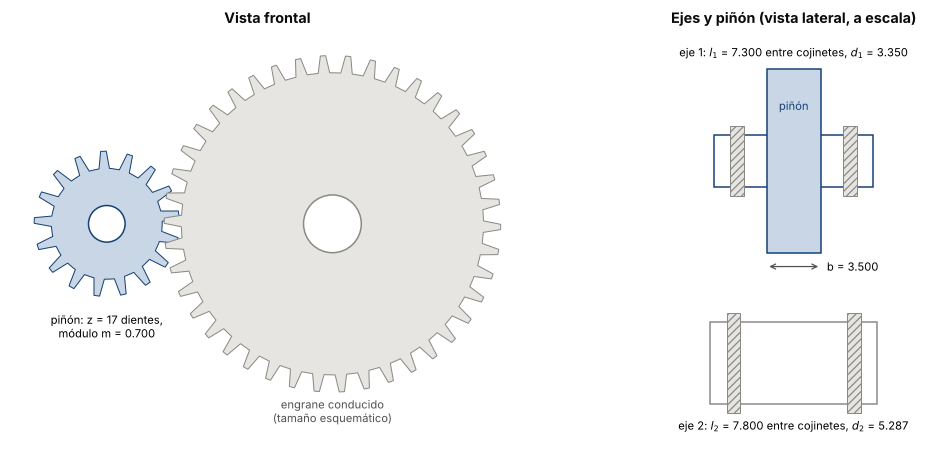

,nuestro PSO,mejor conocido (artículo)
variable,,
b: ancho de cara,3.500000,3.500000
m: módulo de los dientes,0.700000,0.700000
z: dientes del piñón,17.000000,17.000000
l₁: largo del eje 1,7.300000,7.300000
l₂: largo del eje 2,7.800000,7.800000
d₁: diámetro del eje 1,3.350215,3.350214
d₂: diámetro del eje 2,5.286683,5.286683


Reductor de velocidad: costo del mejor diseño = 2996.348165 (mejor conocido 2996.348165); restricciones activas: 3 de 11


,qué limita,g_j(x),g_j / escala,estado
restricción,,,,
g1,esfuerzo de flexión en los dientes,-7.392e-02,-7.39e-02,holgada
g2,esfuerzo de contacto en los dientes,-1.980e-01,-1.98e-01,holgada
g3,deflexión transversal del eje 1,-4.992e-01,-4.99e-01,holgada
g4,deflexión transversal del eje 2,-9.015e-01,-9.01e-01,holgada
g5,esfuerzo en el eje 1,-6.397e-12,-6.40e-12,activa
g6,esfuerzo en el eje 2,-6.690e-13,-6.69e-13,activa
g7,tamaño del piñón (m·z ≤ 40),-7.025e-01,-7.02e-01,holgada
g8,ancho de cara b ≥ 5 m,-1.037e-12,-1.04e-12,activa
g9,ancho de cara b ≤ 12 m,-5.833e-01,-5.83e-01,holgada


In [46]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
esquema_reductor(mejor_corrida('speed_reducer')['position'], axs)
fig.tight_layout()
plt.show()
display(tabla_diseno('speed_reducer'))
tabla_restricciones('speed_reducer')

Coincide con el mejor conocido. El módulo, el número de dientes y los largos de los ejes quedan en su cota inferior ($m = 0.7$, $z = 17$, $l_1 = 7.3$, $l_2 = 7.8$); el ancho de cara queda en $b = 5m = 3.5$, el mínimo que permite $g_8$; y los diámetros de los ejes quedan justo donde el esfuerzo en cada eje alcanza su límite ($g_5$ y $g_6$ activas). Las 30 corridas terminan en este mismo diseño (desviación estándar de $1.2\times10^{-7}$).

#### Resorte de tensión/compresión (E04)

Se minimiza el **peso** de un resorte helicoidal sujeto a deflexión mínima, esfuerzo cortante, frecuencia de oscilación y diámetro exterior máximo.

$$
\min_{\mathbf{x}}\; f(\mathbf{x}) = (x_3 + 2)\,x_2\,x_1^2
$$

$$
\begin{aligned}
g_1 &= 1 - \frac{x_2^3 x_3}{71\,785\,x_1^4} \le 0, &
g_2 &= \frac{4x_2^2 - x_1 x_2}{12\,566\,(x_2 x_1^3 - x_1^4)} + \frac{1}{5\,108\,x_1^2} - 1 \le 0,\\
g_3 &= 1 - \frac{140.45\,x_1}{x_2^2 x_3} \le 0, &
g_4 &= \frac{x_1 + x_2}{1.5} - 1 \le 0.
\end{aligned}
$$

| Variable | Significado | Rango |
|---|---|---|
| $x_1 = d$ | diámetro del alambre | $[0.05, 2]$ |
| $x_2 = D$ | diámetro medio de la espira | $[0.25, 1.3]$ |
| $x_3 = N$ | número de espiras activas | $[2, 15]$ |

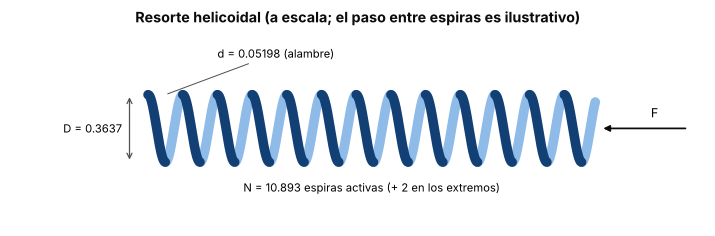

,nuestro PSO,mejor conocido (artículo)
variable,,
d: diámetro del alambre,0.051976,0.051690
D: diámetro medio de la espira,0.363663,0.356750
N: espiras activas,10.893132,11.287126


Resorte: costo del mejor diseño = 0.012667 (mejor conocido 0.012665); restricciones activas: 2 de 4


,qué limita,g_j(x),g_j / escala,estado
restricción,,,,
g1,deflexión mínima,-4.316e-11,-4.32e-11,activa
g2,esfuerzo cortante,-5.827e-11,-5.83e-11,activa
g3,frecuencia de oscilación (surge),-4.067e+00,-4.07e+00,holgada
g4,diámetro exterior D + d ≤ 1.5,-7.229e-01,-7.23e-01,holgada


In [47]:
fig, ax = plt.subplots(figsize=(10, 3.4))
esquema_resorte(mejor_corrida('spring')['position'], ax)
plt.show()
display(tabla_diseno('spring'))
tabla_restricciones('spring')

Nuestro mejor resorte pesa 0.012667, a 0.01 % del mejor conocido, con un diseño ligeramente distinto: alambre un poco más grueso ($d = 0.0520$ frente a 0.0517), espira un poco más ancha ($D = 0.364$ frente a 0.357) y menos espiras (10.89 frente a 11.29). El fondo del valle del resorte es casi plano a lo largo de una curva en la que las tres variables se compensan; el propio artículo reporta para SiC-PSO otro diseño ($d = 0.051583$, $D = 0.354190$, $N = 11.438675$) con el mismo peso, 0.012665. En el óptimo quedan activas la deflexión mínima ($g_1$) y el esfuerzo cortante ($g_2$).

### 6.6 El recipiente a presión: un paisaje en escalones

Los espesores $T_s$ y $T_h$ solo pueden ser múltiplos de 0.0625 in, así que el costo no baja de forma continua: para cada valor de $T_s$ hay un "escalón" con su propio mejor diseño. Agrupamos las 30 corridas por el $T_s$ de su diseño final:

,corridas,costo mínimo,costo máximo,R medio,R máx. = T_s / 0.0193,L medio
T_s (in),,,,,,
0.8125,2,6059.71,6059.71,42.10,42.10,176.64
0.8750,11,6090.53,6091.15,45.34,45.34,140.26
0.9375,4,6370.78,6370.78,48.58,48.58,110.07
1.0000,8,6410.09,6410.10,51.81,51.81,84.58
1.0625,3,6771.60,6773.21,55.04,55.05,62.76
1.1250,2,6820.41,6820.41,58.29,58.29,43.69


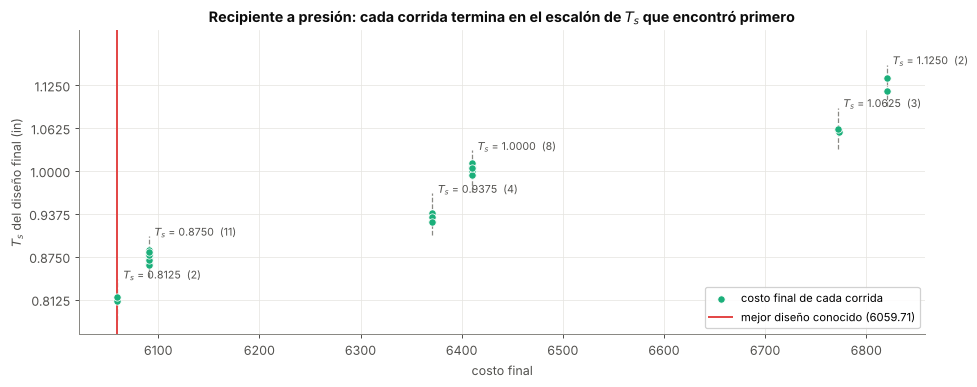

In [48]:
res = corridas_ing['pressure_vessel']
recipiente = pd.DataFrame({'T_s': [r['position'][0] for r in res], 'T_h': [r['position'][1] for r in res],
                           'R': [r['position'][2] for r in res], 'L': [r['position'][3] for r in res],
                           'costo': [r['cost'] for r in res]})
escalones = (recipiente.groupby('T_s')
             .agg(corridas=('costo', 'size'), costo_min=('costo', 'min'), costo_max=('costo', 'max'),
                  R_medio=('R', 'mean'), L_medio=('L', 'mean')))
escalones['R_max = T_s / 0.0193'] = escalones.index / 0.0193
display(pd.DataFrame({'T_s (in)': [f'{t:.4f}' for t in escalones.index],
                      'corridas': escalones['corridas'].to_numpy(),
                      'costo mínimo': [f'{v:.2f}' for v in escalones['costo_min']],
                      'costo máximo': [f'{v:.2f}' for v in escalones['costo_max']],
                      'R medio': [f'{v:.2f}' for v in escalones['R_medio']],
                      'R máx. = T_s / 0.0193': [f'{v:.2f}' for v in escalones['R_max = T_s / 0.0193']],
                      'L medio': [f'{v:.2f}' for v in escalones['L_medio']]}).set_index('T_s (in)'))

fig, ax = plt.subplots(figsize=(11, 4.4))
rng_j = np.random.default_rng(3)
y = recipiente['T_s'] + rng_j.uniform(-0.012, 0.012, len(recipiente))
ax.scatter(recipiente['costo'], y, s=34, color=AQUA, edgecolors='white', linewidths=0.6, zorder=3,
           label='costo final de cada corrida')
for ts, fila in escalones.iterrows():
    ax.vlines(fila['costo_min'], ts - 0.03, ts + 0.03, color=GRIS, lw=1.0, ls='--', zorder=1)
    ax.text(fila['costo_min'] + 6, ts + 0.026, f"$T_s$ = {ts:.4f}  ({int(fila['corridas'])})", fontsize=8.5,
            color=TINTA_2, va='bottom')
ax.axvline(PROBLEMS['pressure_vessel']['best'], color=OPTIMO, lw=1.6, zorder=2, label='mejor diseño conocido (6059.71)')
ax.set_xlabel('costo final'); ax.set_ylabel('$T_s$ del diseño final (in)')
ax.set_yticks(escalones.index)
ax.set_title('Recipiente a presión: cada corrida termina en el escalón de $T_s$ que encontró primero')
ax.legend(loc='lower right', fontsize=9, frameon=True, facecolor='white', framealpha=0.9)
ax.set_ylim(escalones.index.min() - 0.05, escalones.index.max() + 0.08)
fig.tight_layout()
plt.show()

Las corridas no se reparten al azar: forman escalones bien definidos (6 059.71 con $T_s = 0.8125$, 6 090.53 con $T_s = 0.875$, 6 370.78 con $T_s = 0.9375$, 6 410.09 con $T_s = 1.0$, y más arriba 6 771.6 y 6 820.4). En todos ellos el radio medio coincide con $R_{\max} = T_s / 0.0193$: la restricción del espesor del casco está activa y amarra $R$ a $T_s$, y el volumen mínimo amarra a su vez $L$ a $R$.

Para bajar un escalón, por ejemplo de $T_s = 0.875$ a $0.8125$, una partícula tendría que reducir $T_s$ en 0.0625, reducir $R$ de 45.3 a 42.1 y alargar $L$ de 140 a 177 **al mismo tiempo**. Si cambia solo una de esas variables, el diseño deja de ser factible, y las reglas de factibilidad prefieren siempre el diseño factible que ya se tiene. Así, cada corrida se queda en el escalón que encuentra primero: 2 de 30 llegan al óptimo, 11 terminan en el escalón siguiente (a solo 0.5 %) y el resto más arriba. Eso explica la media alta y la desviación de 252 de la tabla comparativa. Es el tipo de paisaje "en terrazas" para el que SiC-PSO y COPSO añaden mecanismos de diversidad al PSO básico (vecindarios en anillo, operadores de perturbación, actualización gaussiana).

### 6.7 Convergencia

Mejor costo factible del enjambre en cada generación, como error relativo frente al mejor diseño conocido, $(f - f^*)/f^*$, en escala logarítmica. La línea es la mediana de las 30 corridas, la banda va del cuartil 25 % al 75 % y las líneas tenues son las corridas individuales. Mientras ninguna partícula es factible no hay costo que graficar, y los valores se recortan en $10^{-9}$, la precisión con que el artículo reporta los óptimos.

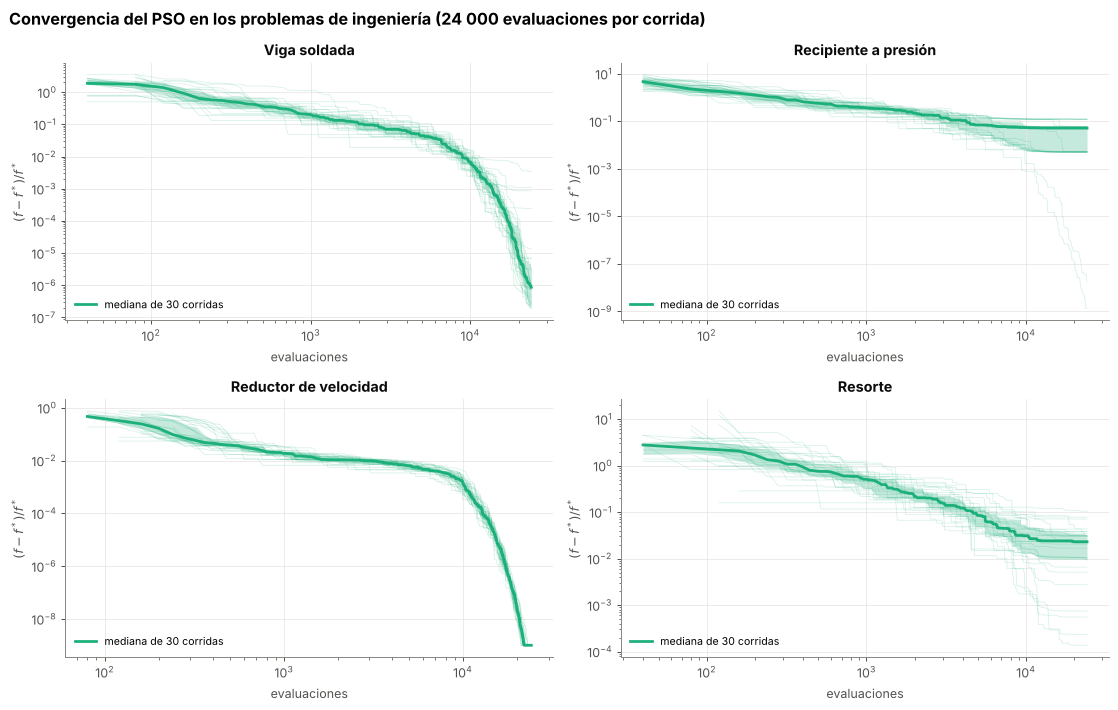

In [49]:
import warnings

fig, ejes = plt.subplots(2, 2, figsize=(12.5, 8))
for ax, (nombre, res) in zip(ejes.ravel(), corridas_ing.items()):
    f_opt = PROBLEMS[nombre]['best']
    H = np.array([r['history'] for r in res], dtype=float)          # (30, 601), NaN = aún no factible
    rel = np.maximum((H - f_opt) / f_opt, 1e-9)
    evals = 40 * np.arange(1, H.shape[1] + 1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        q25, q50, q75 = np.nanpercentile(rel, [25, 50, 75], axis=0)
    for curva in rel:
        ax.plot(evals, curva, color=AQUA, lw=0.6, alpha=0.18)
    ax.fill_between(evals, q25, q75, color=AQUA, alpha=0.25, lw=0)
    ax.plot(evals, q50, color=AQUA, lw=2.2, label='mediana de 30 corridas')
    ax.set_yscale('log'); ax.set_xscale('log')
    ax.set_title(NOMBRES_ING[nombre])
    ax.set_xlabel('evaluaciones'); ax.set_ylabel('$(f - f^*) / f^*$')
    ax.legend(loc='lower left', fontsize=8.5)
fig.suptitle('Convergencia del PSO en los problemas de ingeniería (24 000 evaluaciones por corrida)',
             fontsize=13, fontweight='bold', x=0.01, ha='left')
fig.tight_layout()
plt.show()

* **Viga soldada y reductor**: el error relativo baja de forma sostenida y se acelera en el último tramo de la corrida, cuando la inercia ya es pequeña y el enjambre afina. La mediana termina en $\sim10^{-6}$ en la viga y en el límite de $10^{-9}$ en el reductor.
* **Recipiente**: desde unas 10 000 evaluaciones la mediana se estanca en $5\times10^{-2}$, el escalón de $T_s = 0.9375$; solo las corridas que encontraron el escalón correcto siguen bajando hasta el óptimo.
* **Resorte**: la mediana termina cerca de $2\times10^{-2}$, con corridas individuales que llegan a $10^{-4}$; en un valle casi plano, el último 2 % es el que más cuesta.
* La forma de las curvas confirma el papel de la inercia: casi toda la mejora fina ocurre después de las ~10 000 evaluaciones, cuando $w$ ya bajó de 0.9 a cerca de 0.7.

## 7. Conclusiones

1. **Los programas del equipo resuelven sus problemas.** Los siete algoritmos genéticos terminan en la cuenca del óptimo global de su función: el de Ackley lo alcanza a precisión de máquina, el de Rastrigin encuentra el mínimo ($5.5\times10^{-7}$) entre unos 120 mínimos locales, y los programas de Griewank y Rosenbrock introdujeron el protocolo de 30 corridas con media y desviación estándar que sostiene todas las comparaciones de este notebook.
2. **Del enjambre real al algoritmo.** Nuestro PSO de 1995 encuentra el embudo de Ackley en pocas generaciones, pero sin inercia no logra asentarse y sigue oscilando a la escala de su velocidad máxima ($f \approx 10^{-3}$). Con inercia o constricción, el mismo esquema de memoria y comunicación obtiene la menor mediana en las siete funciones en 2D con 10 000 evaluaciones.
3. **Ningún algoritmo gana siempre.** En $D = 10$ el PSO gana en Ackley, Bent Cigar, Elliptic y Rosenbrock; el GA de un punto, en Rastrigin y HGBat; el GA aritmético, en Griewank. Es el teorema *no free lunch* (Wolpert y Macready, 1997) en acción: promediado sobre todos los problemas posibles, ningún optimizador supera a otro, y la ventaja de cada uno aparece cuando su sesgo coincide con la estructura del problema (separabilidad para el cruce de un punto, valles suaves para el cruce aritmético y el PSO).
4. **La rotación separa estructura de suerte.** Al rotar el paisaje, el GA de un punto y el PSO pierden buena parte de su ventaja en funciones separables, mientras que el GA aritmético casi no cambia. Por eso CEC 2022 rota y desplaza todas sus funciones.
5. **Del enjambre a la ingeniería.** Con reglas de factibilidad, variables discretas, un límite de velocidad por variable e inercia decreciente, nuestro PSO alcanza el mejor diseño conocido en los cuatro problemas del artículo de Cagnina, Esquivel y Coello Coello (en el resorte, a 0.01 %), con el mismo presupuesto de 24 000 evaluaciones y las 30 corridas factibles. En promedio queda muy cerca o mejor que las referencias del artículo en la viga, el reductor y el resorte, y peor en el recipiente a presión, cuyo paisaje en escalones (espesores discretos amarrados a restricciones activas) atrapa a cada corrida en el primer escalón que encuentra. Sin inercia, las medianas quedan entre 1 % y 12 % por encima del mejor conocido.
6. **Alcance de estos resultados.** Usamos parámetros estándar sin ajustar, presupuestos modestos (10 000 evaluaciones en 2D y 20 000 en 10D, frente a las 200 000 que fija CEC 2022 para $D = 10$ y 1 000 000 para $D = 20$), funciones sin desplazar y 15 corridas en 10D. Los números describen estas configuraciones concretas, no a las familias de algoritmos en general. Los siguientes pasos naturales son correr los mismos algoritmos sobre las 12 funciones completas de CEC 2022 (con la [implementación de Kaggle](https://www.kaggle.com/code/kooaslansefat/cec-2022-benchmark)), compararlos con variantes adaptativas como CMA-ES o la evolución diferencial con parámetros adaptativos y, en ingeniería, añadir al PSO un mecanismo de diversidad que le permita saltar entre los escalones del recipiente.

In [50]:
print(f'Tiempo total de ejecución del notebook: {time.perf_counter() - T_INICIO:.1f} s')

Tiempo total de ejecución del notebook: 101.5 s
